In [4]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

import zipfile
from scipy.spatial.distance import cdist
from astropy.io import fits

from tqdm import tqdm

%matplotlib ipympl


In [5]:
with open("GaiaBBF2022_2023", "rb") as fichier:
    gaia = pickle.load(fichier)
    
gaia.data.head()

2025-12-01 21:45:54,534 WARNING sparse_dot_mkl not available


,flux,flux_error,ra,dec
1201049160076424448,"[1.1704254396821757e-16, -3.505997693543709e-1...","[1.1704254396821758e-14, -3.505997693543709e-1...",246.863961,20.004470
1201049228795888896,"[1.0784097331097358e-15, 6.863343575384727e-16...","[1.0784097331097358e-13, 6.863343575384727e-14...",246.891329,20.009202
1201051221660722816,"[7.310847965336251e-17, -1.724798157549993e-16...","[7.310847965336251e-15, -1.724798157549993e-14...",246.729530,20.000039
1201051496538672256,"[-1.7911713538342965e-16, -9.193913068362099e-...","[-1.7911713538342966e-14, -9.193913068362098e-...",246.706800,20.014004
1201051908855488000,"[2.7374245073613466e-16, 3.0388721800760064e-1...","[2.7374245073613468e-14, 3.0388721800760064e-1...",246.770677,20.000520


In [ ]:
from astroquery.gaia import Gaia
tables = Gaia.load_tables(only_names=True)



for table in tables:
  print(table.get_qualified_name())

2025-11-19 16:05:45,928 INFO Retrieving tables...
2025-11-19 16:05:46,105 INFO Parsing tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]


2025-11-19 16:05:46,209 INFO Done.


INFO: Done. [astroquery.utils.tap.core]
external.apassdr9
external.catwise2020
external.gaiadr2_astrophysical_parameters
external.gaiadr2_geometric_distance
external.gaiaedr3_distance
external.gaiaedr3_gcns_main_1
external.gaiaedr3_gcns_rejected_1
external.gaiaedr3_spurious
external.gaia_eso_survey
external.galex_ais
external.lamost_dr9_lrs
external.lamost_dr9_mrs
external.ravedr5_com
external.ravedr5_dr5
external.ravedr5_gra
external.ravedr5_on
external.ravedr6
external.sdssdr13_photoprimary
external.skymapperdr1_master
external.skymapperdr2_master
external.tmass_xsc
external.xgboost_table1
external.xgboost_table2
gaiadr1.aux_qso_icrf2_match
gaiadr1.ext_phot_zero_point
gaiadr1.allwise_best_neighbour
gaiadr1.allwise_neighbourhood
gaiadr1.gsc23_best_neighbour
gaiadr1.gsc23_neighbourhood
gaiadr1.ppmxl_best_neighbour
gaiadr1.ppmxl_neighbourhood
gaiadr1.sdss_dr9_best_neighbour
gaiadr1.sdss_dr9_neighbourhood
gaiadr1.tmass_best_neighbour
gaiadr1.tmass_neighbourhood
gaiadr1.ucac4_best_neighbo

In [6]:
# Traitement par batch de 1000 IDs pour éviter les limites de requête
batch_size = 1000
all_astro_data = []

if not os.path.isfile("gaia_astro_params.parquet"):
    total_ids = len(gaia.data.index)
    print(f"Traitement de {total_ids} IDs par batch de {batch_size}...")

    for i in range(0, total_ids, batch_size):
        # Créer le batch d'IDs
        end_idx = min(i + batch_size, total_ids)
        batch_ids = gaia.data.index.values[i:end_idx]
        
        # Convertir en string pour la requête SQL
        gaia_ids_batch = np.array2string(batch_ids, separator=',', max_line_width=np.inf)[1:-1]
        gaia_ids_batch = gaia_ids_batch.replace('\n ', '')
        
        print(f"Traitement du batch {i//batch_size + 1}/{(total_ids-1)//batch_size + 1} ({len(batch_ids)} IDs)")
        
        # Requête Gaia pour ce batch
        qry = f"SELECT source_id,distance_gspphot,teff_gspphot,logg_gspphot,mh_gspphot,teff_gspspec,logg_gspspec,mh_gspspec FROM gaiadr3.astrophysical_parameters gs WHERE gs.source_id in ({gaia_ids_batch});"
        
        try:
            job = Gaia.launch_job(qry)
            batch_astro = job.get_results().to_pandas()
            
            if len(batch_astro) > 0:
                batch_astro.set_index('source_id', inplace=True)
                all_astro_data.append(batch_astro)
                print(f"  -> {len(batch_astro)} résultats trouvés")
            else:
                print(f"  -> Aucun résultat trouvé")
                
        except Exception as e:
            print(f"  -> Erreur lors de la requête: {e}")
            continue

    # Fusionner tous les résultats
    if all_astro_data:
        astro = pd.concat(all_astro_data, ignore_index=False)
        print(f"\nTotal final: {len(astro)} étoiles avec paramètres astrophysiques")
    else:
        print("\nAucune donnée astrophysique récupérée")
        astro = pd.DataFrame()
else:
    print("Chargement des paramètres astrophysiques depuis le fichier parquet...")
    astro = pd.read_parquet("gaia_astro_params.parquet")
    # astro.set_index('source_id', inplace=True)
    print(f"Total chargé: {len(astro)} étoiles avec paramètres astrophysiques")

Chargement des paramètres astrophysiques depuis le fichier parquet...
Total chargé: 158493 étoiles avec paramètres astrophysiques


In [7]:
astro.head()

,distance_gspphot,teff_gspphot,logg_gspphot,mh_gspphot,teff_gspspec,logg_gspspec,mh_gspspec
source_id,,,,,,,
1201049160076424448,1972.534668,4346.903809,4.1830,-0.7584,NaN,NaN,NaN
1201049228795888896,1875.229248,5473.907715,4.3294,-1.0593,NaN,NaN,NaN
1201051221660722816,1159.936035,5134.705078,4.7007,-1.2314,NaN,NaN,NaN
1201051496538672256,263.920898,3481.718018,4.7809,-0.1879,NaN,NaN,NaN
1201051908855488000,1335.302246,5461.534668,4.6462,-1.1339,NaN,NaN,NaN


In [8]:
#astro.to_parquet("gaia_astro_params.parquet")
#astro = pd.read_parquet("gaia_astro_params.parquet")

In [9]:
# Incorporer la table astro dans gaia.data en gardant les index originaux
gaia.data = gaia.data.merge(astro, left_index=True, right_index=True, how='left')

# Vérifier le résultat
print(f"Nombre de lignes après fusion : {len(gaia.data)}")
# print(f"Colonnes ajoutées : {['teff_gspphot', 'logg_gspphot', 'mh_gspphot']}")
print(f"Index conservé : {gaia.data.index.name}")
print(f"Nombre d'étoiles avec paramètres astrophysiques : {np.sum(~np.isnan(gaia.data['teff_gspphot']))}")
print("\nPremières lignes du DataFrame fusionné :")
gaia.data.head()

Nombre de lignes après fusion : 158493
Index conservé : None
Nombre d'étoiles avec paramètres astrophysiques : 142085

Premières lignes du DataFrame fusionné :


,flux,flux_error,ra,dec,distance_gspphot,teff_gspphot,logg_gspphot,mh_gspphot,teff_gspspec,logg_gspspec,mh_gspspec
1201049160076424448,"[1.1704254396821757e-16, -3.505997693543709e-1...","[1.1704254396821758e-14, -3.505997693543709e-1...",246.863961,20.004470,1972.534668,4346.903809,4.1830,-0.7584,NaN,NaN,NaN
1201049228795888896,"[1.0784097331097358e-15, 6.863343575384727e-16...","[1.0784097331097358e-13, 6.863343575384727e-14...",246.891329,20.009202,1875.229248,5473.907715,4.3294,-1.0593,NaN,NaN,NaN
1201051221660722816,"[7.310847965336251e-17, -1.724798157549993e-16...","[7.310847965336251e-15, -1.724798157549993e-14...",246.729530,20.000039,1159.936035,5134.705078,4.7007,-1.2314,NaN,NaN,NaN
1201051496538672256,"[-1.7911713538342965e-16, -9.193913068362099e-...","[-1.7911713538342966e-14, -9.193913068362098e-...",246.706800,20.014004,263.920898,3481.718018,4.7809,-0.1879,NaN,NaN,NaN
1201051908855488000,"[2.7374245073613466e-16, 3.0388721800760064e-1...","[2.7374245073613468e-14, 3.0388721800760064e-1...",246.770677,20.000520,1335.302246,5461.534668,4.6462,-1.1339,NaN,NaN,NaN


## AMBRE database

In [10]:
filenames = os.listdir("AMBRE")
filenames

['M_p7000g4.0z-1.50t1.0_a0.80c0.00n0.00o0.80r0.00s0.00_VIS.spec.flat.zip',
 'M_s3700g3.0z-1.00t1.0_a0.20c0.00n0.00o0.20r0.00s0.00_VIS.spec.flat.zip',
 'M_s3500g2.0z-0.25t1.0_a0.50c0.00n0.00o0.50r0.00s0.00_VIS.spec.flat.zip',
 'M_p5750g4.5z0.75t1.0_a-0.20c0.00n0.00o-0.20r0.00s0.00_VIS.spec.flat.zip',
 'M_p4000g4.0z0.25t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip',
 'M_p5500g3.5z-1.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip',
 'M_s5500g1.0z-1.50t2.0_a0.80c0.00n0.00o0.80r0.00s0.00_VIS.spec.flat.zip',
 'M_s6500g3.0z0.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip',
 'M_p3900g5.5z-0.25t1.0_a-0.30c0.00n0.00o-0.30r0.00s0.00_VIS.spec.flat.zip',
 'M_p3700g3.5z-0.75t1.0_a0.50c0.00n0.00o0.50r0.00s0.00_VIS.spec.flat.zip',
 'M_s6500g1.0z-0.50t2.0_a-0.20c0.00n0.00o-0.20r0.00s0.00_VIS.spec.flat.zip',
 'M_p5500g4.0z0.75t1.0_a-0.40c0.00n0.00o-0.40r0.00s0.00_VIS.spec.flat.zip',
 'M_s3700g0.5z-0.50t1.0_a0.20c0.00n0.00o0.20r0.00s0.00_VIS.spec.flat.zip',
 'M_s5000g2.0z0.00t1.

In [11]:
for f in sorted(filenames[:10]):
    key = f.split("_")[1]
    teff = float(key.split("g")[0][1:])
    logg = float(key.split("g")[1].split("z")[0])
    mh = float(key.split("z")[1].split("t")[0])
    print(f, teff, logg, mh)

M_p3700g3.5z-0.75t1.0_a0.50c0.00n0.00o0.50r0.00s0.00_VIS.spec.flat.zip 3700.0 3.5 -0.75
M_p3900g5.5z-0.25t1.0_a-0.30c0.00n0.00o-0.30r0.00s0.00_VIS.spec.flat.zip 3900.0 5.5 -0.25
M_p4000g4.0z0.25t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip 4000.0 4.0 0.25
M_p5500g3.5z-1.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip 5500.0 3.5 -1.0
M_p5750g4.5z0.75t1.0_a-0.20c0.00n0.00o-0.20r0.00s0.00_VIS.spec.flat.zip 5750.0 4.5 0.75
M_p7000g4.0z-1.50t1.0_a0.80c0.00n0.00o0.80r0.00s0.00_VIS.spec.flat.zip 7000.0 4.0 -1.5
M_s3500g2.0z-0.25t1.0_a0.50c0.00n0.00o0.50r0.00s0.00_VIS.spec.flat.zip 3500.0 2.0 -0.25
M_s3700g3.0z-1.00t1.0_a0.20c0.00n0.00o0.20r0.00s0.00_VIS.spec.flat.zip 3700.0 3.0 -1.0
M_s5500g1.0z-1.50t2.0_a0.80c0.00n0.00o0.80r0.00s0.00_VIS.spec.flat.zip 5500.0 1.0 -1.5
M_s6500g3.0z0.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip 6500.0 3.0 0.0


In [12]:
# Créer un DataFrame AMBRE avec les paramètres extraits des noms de fichiers
ambre_data = []

for f in sorted(filenames):
    try:
        key = f.split("_")[1]
        teff = float(key.split("g")[0][1:])
        logg = float(key.split("g")[1].split("z")[0])
        mh = float(key.split("z")[1].split("t")[0])
        
        ambre_data.append({
            'filename': f,
            'teff': teff,
            'logg': logg,
            'mh': mh
        })
    except (IndexError, ValueError) as e:
        print(f"Erreur lors du traitement du fichier {f}: {e}")
        continue

# Créer le DataFrame
ambre = pd.DataFrame(ambre_data)

print(f"Nombre de fichiers AMBRE traités : {len(ambre)}")
print("\nPremières lignes du DataFrame AMBRE :")

ambre.head(10)

Erreur lors du traitement du fichier .DS_Store: could not convert string to float: 'tore'
Erreur lors du traitement du fichier README_AMBRE.txt: could not convert string to float: 'MBRE.txt'
Erreur lors du traitement du fichier ambre_complete_binned_1.0A.parquet: could not convert string to float: 'omplete'
Erreur lors du traitement du fichier ambre_complete_binned_10.0A.parquet: could not convert string to float: 'omplete'
Erreur lors du traitement du fichier ambre_params.parquet: could not convert string to float: 'arams.parquet'
Nombre de fichiers AMBRE traités : 12927

Premières lignes du DataFrame AMBRE :


,filename,teff,logg,mh
0,M_p3500g3.5z-0.25t1.0_a-0.10c0.00n0.00o-0.10r0...,3500.0,3.5,-0.25
1,M_p3500g3.5z-0.25t1.0_a-0.30c0.00n0.00o-0.30r0...,3500.0,3.5,-0.25
2,M_p3500g3.5z-0.25t1.0_a0.10c0.00n0.00o0.10r0.0...,3500.0,3.5,-0.25
3,M_p3500g3.5z-0.25t1.0_a0.30c0.00n0.00o0.30r0.0...,3500.0,3.5,-0.25
4,M_p3500g3.5z-0.25t1.0_a0.50c0.00n0.00o0.50r0.0...,3500.0,3.5,-0.25
5,M_p3500g3.5z-0.50t1.0_a-0.20c0.00n0.00o-0.20r0...,3500.0,3.5,-0.50
6,M_p3500g3.5z-0.50t1.0_a0.00c0.00n0.00o0.00r0.0...,3500.0,3.5,-0.50
7,M_p3500g3.5z-0.50t1.0_a0.20c0.00n0.00o0.20r0.0...,3500.0,3.5,-0.50
8,M_p3500g3.5z-0.50t1.0_a0.40c0.00n0.00o0.40r0.0...,3500.0,3.5,-0.50
9,M_p3500g3.5z-0.50t1.0_a0.60c0.00n0.00o0.60r0.0...,3500.0,3.5,-0.50


In [13]:
ambre.to_parquet("AMBRE/ambre_params.parquet")

In [14]:
def convert_ambre_to_gaia_units(ambre_flux):
    """
    Convertit le flux AMBRE de erg/s/cm²/Å vers W/nm/m² (unités Gaia)
    
    Facteurs de conversion :
    - 1 erg = 1e-7 J = 1e-7 W·s
    - 1 cm² = 1e-4 m²
    - 1 Å = 0.1 nm
    
    Donc : erg/s/cm²/Å = 1e-7 W·s/s / 1e-4 m² / 0.1 nm = 1e-7 / 1e-4 / 0.1 W/nm/m² = 1e-2 W/nm/m²
    """
    # Facteur de conversion : erg/s/cm²/Å -> W/nm/m²
    conversion_factor = 1e-7 / 1e-4 / 0.1  # = 1e-2
    
    gaia_flux = ambre_flux * conversion_factor
    
    return gaia_flux

# Fonction pour lire un spectre AMBRE depuis un fichier ZIP
def read_ambre_spectrum(zip_filename, ambre_dir="AMBRE"):
    """Lit un spectre AMBRE depuis un fichier ZIP"""
    zip_path = os.path.join(ambre_dir, zip_filename)
    
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_file:
            # Lister les fichiers dans le ZIP
            file_list = zip_file.namelist()
            
            # Chercher un fichier FITS
            spec_files = [f for f in file_list if f.endswith('.spec')]
            
            if spec_files:
                wavelength, flux, flux_normalized = np.loadtxt(zip_file.open(spec_files[0]), unpack=True)
                flux_gaia_units = convert_ambre_to_gaia_units(flux)
                return wavelength, flux_gaia_units, flux_normalized
            else:
                print(f"Aucun fichier SPEC trouvé dans {zip_filename}")
                return None, None, None
                
    except Exception as e:
        print(f"Erreur lors de la lecture de {zip_filename}: {e}")
        return None, None, None

def bin_spectrum_by_angstrom_efficient(wavelength, flux, bin_size=1.0):
    """Binne un spectre par angström de manière efficace avec numpy.histogram"""
    # Définir les bornes des bins
    wave_min = np.floor(np.min(wavelength))
    wave_max = np.ceil(np.max(wavelength))
    
    # Créer la grille des bins
    bin_edges = np.arange(wave_min, wave_max + bin_size, bin_size)
    
    # Utiliser numpy.histogram avec weights pour calculer la moyenne
    flux_sum, _ = np.histogram(wavelength, bins=bin_edges, weights=flux)
    counts, _ = np.histogram(wavelength, bins=bin_edges)
    
    # Éviter la division par zéro
    with np.errstate(divide='ignore', invalid='ignore'):
        binned_flux = flux_sum / counts
        binned_flux[counts == 0] = np.nan
    
    # Centres des bins
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    return bin_centers, binned_flux

# Version encore plus efficace avec scipy si disponible
def bin_spectrum_scipy(wavelength, flux, bin_size=1.0):
    """Version avec scipy.stats.binned_statistic (encore plus efficace)"""
    try:
        from scipy.stats import binned_statistic
        
        wave_min = np.floor(np.min(wavelength))
        wave_max = np.ceil(np.max(wavelength))
        bin_edges = np.arange(wave_min, wave_max + bin_size, bin_size)
        
        binned_flux, edges, _ = binned_statistic(wavelength, flux, 
                                               statistic='mean', bins=bin_edges)
        bin_centers = (edges[:-1] + edges[1:]) / 2
        
        return bin_centers, binned_flux
        
    except ImportError:
        # Fallback vers la version numpy si scipy n'est pas disponible
        return bin_spectrum_by_angstrom_efficient(wavelength, flux, bin_size)


# Définir la grille de longueurs d'onde commune (celle de Gaia)
bin_size = 1.0  # Angstrom
if not os.path.isfile(f"AMBRE/ambre_complete_binned_{bin_size}A.parquet"):
    # Créer un DataFrame AMBRE complet avec spectres rebinnés
    print("Traitement de tous les spectres AMBRE pour créer le DataFrame complet...")

    # Listes pour le nouveau DataFrame
    ambre_complete_data = []

    # Boucler sur tous les fichiers AMBRE
    for idx, row in tqdm(ambre.iterrows(), total=len(ambre), desc="Traitement spectres AMBRE"):
        filename = row['filename']
        teff = row['teff']
        logg = row['logg']
        mh = row['mh']
        
        # Lire le spectre AMBRE
        ambre_wave, ambre_flux, _ = read_ambre_spectrum(filename)
        
        if ambre_wave is not None and ambre_flux is not None:
            # Binning du spectre AMBRE sur la grille Gaia
            ambre_wave_binned, ambre_flux_binned = bin_spectrum_scipy(ambre_wave, ambre_flux, bin_size=bin_size)
            
            # Ajouter au DataFrame
            ambre_complete_data.append({
                'filename': filename,
                'teff': teff,
                'logg': logg,
                'mh': mh,
                'flux_binned': ambre_flux_binned,
                'wave_binned': ambre_wave_binned
            })
        else:
            print(f"Erreur lecture {filename}")
            # Ajouter avec des NaN
            ambre_complete_data.append({
                'filename': filename,
                'teff': teff,
                'logg': logg,
                'mh': mh,
                'flux_binned': np.full(len(gaia.wave), np.nan),
                'wave_binned': gaia.wave.copy()
            })

    # Créer le nouveau DataFrame AMBRE complet
    ambre_complete = pd.DataFrame(ambre_complete_data)

    print(f"\nDataFrame AMBRE complet créé :")
    print(f"- Nombre de spectres : {len(ambre_complete)}")
    print(f"- Résolution : {bin_size} Å")

    # Sauvegarder pour usage ultérieur
    ambre_complete.to_parquet(f"AMBRE/ambre_complete_binned_{bin_size}A.parquet")

    print(f"\nDataFrame sauvegardé dans AMBRE/ambre_complete_binned_{bin_size}A.parquet")
else:
    print(f"Chargement du DataFrame AMBRE complet depuis AMBRE/ambre_complete_binned_{bin_size}A.parquet...")
    ambre_complete = pd.read_parquet(f"AMBRE/ambre_complete_binned_{bin_size}A.parquet")
ambre_complete.head()

Chargement du DataFrame AMBRE complet depuis AMBRE/ambre_complete_binned_1.0A.parquet...


,filename,teff,logg,mh,flux_binned,wave_binned
0,M_p3500g3.5z-0.25t1.0_a-0.10c0.00n0.00o-0.10r0...,3500.0,3.5,-0.25,"[6.783765399999998, 8.029821999999998, 6.75014...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005...."
1,M_p3500g3.5z-0.25t1.0_a-0.30c0.00n0.00o-0.30r0...,3500.0,3.5,-0.25,"[6.839363599999997, 7.858921999999996, 7.87037...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005...."
2,M_p3500g3.5z-0.25t1.0_a0.10c0.00n0.00o0.10r0.0...,3500.0,3.5,-0.25,"[6.990753799999996, 8.265295999999996, 6.71264...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005...."
3,M_p3500g3.5z-0.25t1.0_a0.30c0.00n0.00o0.30r0.0...,3500.0,3.5,-0.25,"[7.4036034, 8.604109999999999, 6.8814131999999...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005...."
4,M_p3500g3.5z-0.25t1.0_a0.50c0.00n0.00o0.50r0.0...,3500.0,3.5,-0.25,"[7.980756999999999, 9.043292, 7.14493319999999...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005...."


In [15]:
# Créer un interpolateur 4D unique pour les spectres AMBRE
from scipy.interpolate import RegularGridInterpolator

print("Création de l'interpolateur 4D pour les spectres AMBRE...")


# Extraire les paramètres stellaires uniques et les trier
teff_unique = np.sort(ambre_complete['teff'].unique())
logg_unique = np.sort(ambre_complete['logg'].unique())
mh_unique = np.sort(ambre_complete['mh'].unique())

# Récupérer la grille de longueurs d'onde commune
wave_grid = ambre_complete.iloc[0]['wave_binned']
n_wave = len(wave_grid)

print(f"Grille des paramètres :")
print(f"- Teff : {len(teff_unique)} valeurs ({teff_unique.min():.0f} - {teff_unique.max():.0f} K)")
print(f"- log g : {len(logg_unique)} valeurs ({logg_unique.min():.1f} - {logg_unique.max():.1f})")
print(f"- [M/H] : {len(mh_unique)} valeurs ({mh_unique.min():.1f} - {mh_unique.max():.1f})")
print(f"- Longueurs d'onde : {n_wave} points ({wave_grid.min():.0f} - {wave_grid.max():.0f} Å)")

# Créer la grille 4D : (teff, logg, mh, wavelength) -> flux
flux_grid = np.full((len(teff_unique), len(logg_unique), len(mh_unique), n_wave), 1)

print("Construction de la grille 4D...")
for idx, row in tqdm(ambre_complete.iterrows(), total=len(ambre_complete), desc="Remplissage grille"):
    # Trouver les indices dans les grilles
    i_teff = np.where(teff_unique == row['teff'])[0][0]
    i_logg = np.where(logg_unique == row['logg'])[0][0]
    i_mh = np.where(mh_unique == row['mh'])[0][0]
    
    # Ajouter le spectre à la grille
    flux_grid[i_teff, i_logg, i_mh, :] = row['flux_binned']

print(f"Grille construite : {flux_grid.shape}")
print(f"Nombre de points valides : {np.sum(~np.isnan(flux_grid))}/{flux_grid.size}")

# Créer l'interpolateur 4D unique
print("Création de l'interpolateur 4D...")
ambre_interpolator = RegularGridInterpolator(
    (teff_unique, logg_unique, mh_unique, wave_grid),
    flux_grid,
    method='linear',
    bounds_error=False,
    fill_value=np.nan
)

print("Interpolateur 4D créé avec succès !")

# Fonction d'interface simplifiée
def ambre_spectrum_interpolator(wavelengths, teff, logg, mh):
    """
    Interpolateur de spectres AMBRE 4D
    
    Parameters:
    -----------
    wavelengths : array-like
        Longueurs d'onde désirées (Å)
    teff : float
        Température effective (K)
    logg : float
        log g (cgs)
    mh : float
        [M/H] (dex)
    
    Returns:
    --------
    flux : array
        Flux interpolé aux longueurs d'onde demandées
    """
    
    # Convertir en arrays numpy
    wavelengths = np.asarray(wavelengths)
    
    # Créer les points d'interpolation
    # Répéter teff, logg, mh pour chaque longueur d'onde
    points = np.column_stack([
        np.full(len(wavelengths), teff),
        np.full(len(wavelengths), logg), 
        np.full(len(wavelengths), mh),
        wavelengths
    ])
    
    # Interpoler
    flux_interp = ambre_interpolator(points)
    
    return flux_interp

print("Utilisation : flux = ambre_spectrum_interpolator(wavelengths, teff, logg, mh)")

# Test de l'interpolateur
print("\nTest de l'interpolateur...")
test_wave = np.array([4000, 5000, 6000, 7000])  # Å
test_teff = 5800  # K
test_logg = 4.4
test_mh = 0.0

test_flux = ambre_spectrum_interpolator(test_wave, test_teff, test_logg, test_mh)
print(f"Test : Teff={test_teff}K, logg={test_logg}, [M/H]={test_mh}")
print(f"Longueurs d'onde : {test_wave}")
print(f"Flux interpolé : {test_flux}")

# Test avec un spectre complet
print("\nTest avec spectre complet sur grille Gaia...")
test_flux_full = ambre_spectrum_interpolator(gaia.wave, test_teff, test_logg, test_mh)
print(f"Spectre complet : {len(test_flux_full)} points")
print(f"Valeurs valides : {np.sum(~np.isnan(test_flux_full))}/{len(test_flux_full)}")

Création de l'interpolateur 4D pour les spectres AMBRE...
Grille des paramètres :
- Teff : 21 valeurs (3500 - 8000 K)
- log g : 13 valeurs (0.0 - 5.5)
- [M/H] : 15 valeurs (-5.0 - 1.0)
- Longueurs d'onde : 9000 points (3000 - 12000 Å)
Construction de la grille 4D...


Remplissage grille: 100%|██████████| 12927/12927 [00:00<00:00, 19061.67it/s]


Grille construite : (21, 13, 15, 9000)
Nombre de points valides : 36855000/36855000
Création de l'interpolateur 4D...
Interpolateur 4D créé avec succès !
Utilisation : flux = ambre_spectrum_interpolator(wavelengths, teff, logg, mh)

Test de l'interpolateur...
Test : Teff=5800K, logg=4.4, [M/H]=0.0
Longueurs d'onde : [4000 5000 6000 7000]
Flux interpolé : [83684.85650224 78844.49775785 73409.07174888 57953.91479821]

Test avec spectre complet sur grille Gaia...
Spectre complet : 343 points
Valeurs valides : 343/343


## Synthetic spectra


Étoile 1 (source_id: 1201049160076424448):
  Gaia: Teff=4347K, log g=4.18, [M/H]=-0.76
  AMBRE: Teff=4250K, log g=4.00, [M/H]=-0.75
  Distance normalisée: 0.040
  Fichier: M_p4250g4.0z-0.75t1.0_a-0.10c0.00n0.00o-0.10r0.00s0.00_VIS.spec.flat.zip

Étoile 2 (source_id: 1201049228795888896):
  Gaia: Teff=5474K, log g=4.33, [M/H]=-1.06
  AMBRE: Teff=5500K, log g=4.50, [M/H]=-1.00
  Distance normalisée: 0.033
  Fichier: M_p5500g4.5z-1.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip

Étoile 3 (source_id: 1201051221660722816):
  Gaia: Teff=5135K, log g=4.70, [M/H]=-1.23
  AMBRE: Teff=5250K, log g=4.50, [M/H]=-1.00
  Distance normalisée: 0.059
  Fichier: M_p5250g4.5z-1.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip

Étoile 4 (source_id: 1201051496538672256):
  Gaia: Teff=3482K, log g=4.78, [M/H]=-0.19
  AMBRE: Teff=3500K, log g=5.00, [M/H]=-0.25
  Distance normalisée: 0.041
  Fichier: M_p3500g5.0z-0.25t1.0_a-0.10c0.00n0.00o-0.10r0.00s0.00_VIS.spec.flat.zip

Étoile 5 (source_id

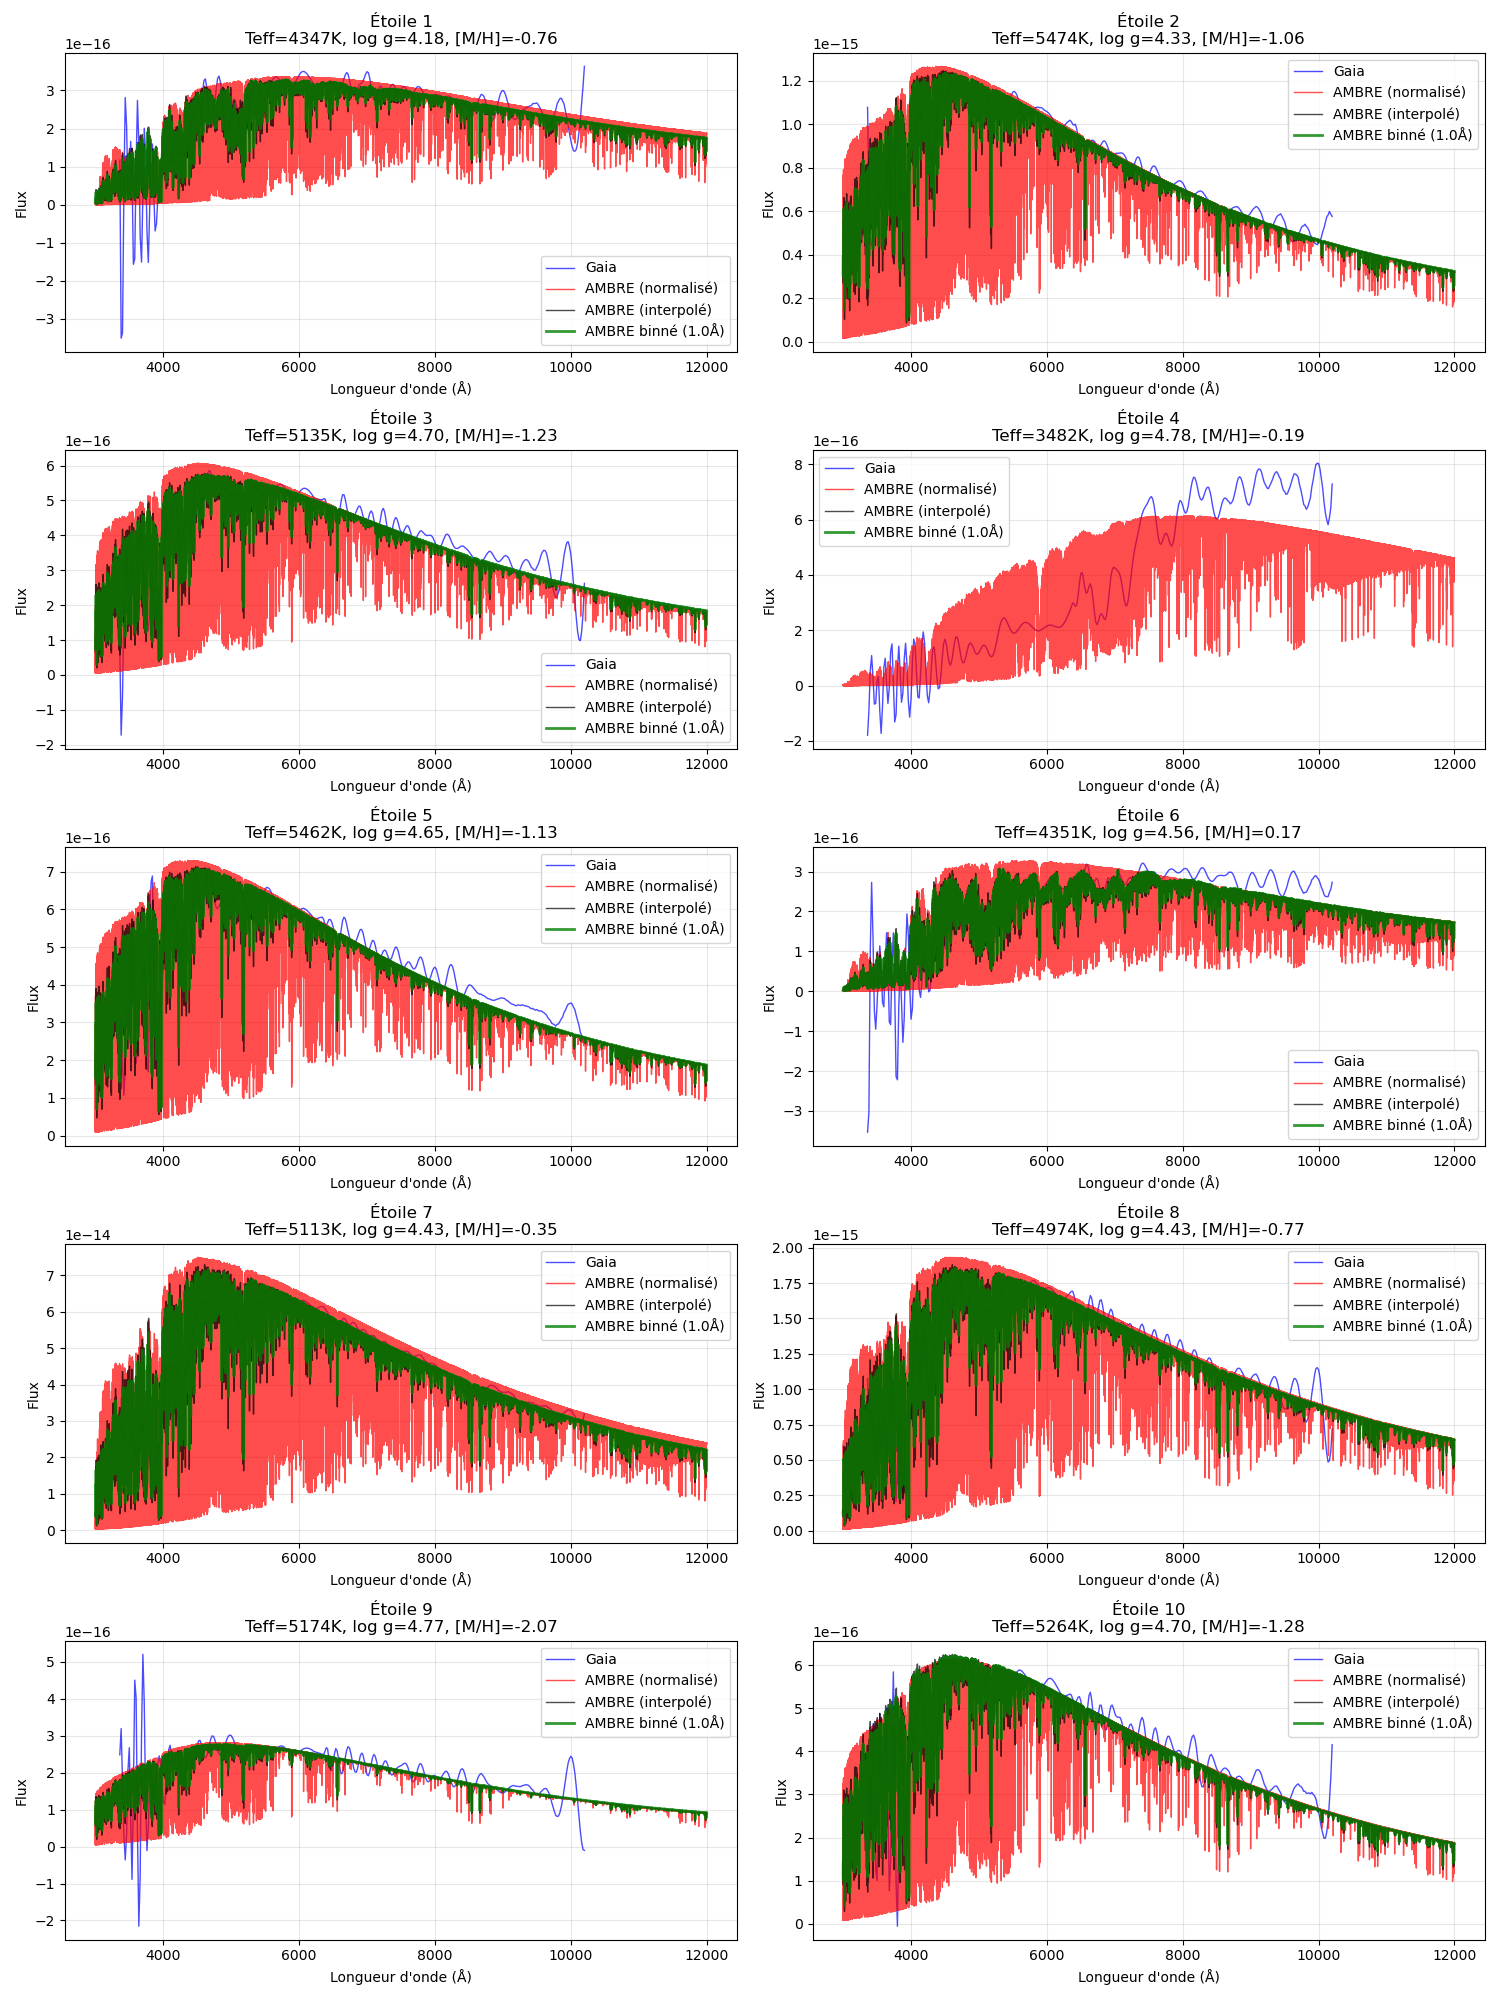

In [16]:
analysis_bin_size = 1.0
if analysis_bin_size < bin_size:
    raise ValueError("analysis_bin_size doit être supérieur ou égal à bin_size")


# Fonction pour trouver le spectre AMBRE le plus proche
def find_closest_ambre(teff_target, logg_target, mh_target, ambre_df):
    """Trouve l'entrée AMBRE la plus proche en utilisant la distance euclidienne normalisée"""
    
    # Normaliser les paramètres pour éviter que Teff domine
    teff_norm = (ambre_df['teff'] - ambre_df['teff'].mean()) / (ambre_df['teff'].max() - ambre_df['teff'].min())
    logg_norm = (ambre_df['logg'] - ambre_df['logg'].mean()) / (ambre_df['logg'].max() - ambre_df['logg'].min())
    mh_norm = (ambre_df['mh'] - ambre_df['mh'].mean()) / (ambre_df['mh'].max() - ambre_df['mh'].min())

    teff_target_norm = (teff_target - ambre_df['teff'].mean()) / (ambre_df['teff'].max() - ambre_df['teff'].min())
    logg_target_norm = (logg_target - ambre_df['logg'].mean()) / (ambre_df['logg'].max() - ambre_df['logg'].min())
    mh_target_norm = (mh_target - ambre_df['mh'].mean()) / (ambre_df['mh'].max() - ambre_df['mh'].min())

    # Calculer la distance euclidienne
    ambre_params = np.column_stack([teff_norm, logg_norm, mh_norm])
    target_params = np.array([[teff_target_norm, logg_target_norm, mh_target_norm]])
    
    distances = cdist(ambre_params, target_params, metric='euclidean').flatten()
    closest_idx = np.argmin(distances)
    
    return closest_idx, distances[closest_idx]


def ambre_normalization(ambre_wave, ambre_flux, gaia_wave, gaia_flux):
    # Définir la plage de longueurs d'onde commune (celle de Gaia)
    wave_min = np.min(gaia_wave)
    wave_max = np.max(gaia_wave)
    
    # Masquer les spectres pour la même plage de longueurs d'onde
    gaia_mask = (gaia_wave >= wave_min) & (gaia_wave <= wave_max)
    ambre_mask = (ambre_wave >= wave_min) & (ambre_wave <= wave_max)
    
    # Extraire les données dans la plage commune
    gaia_wave_common = gaia_wave[gaia_mask]
    gaia_flux_common = gaia_flux[gaia_mask]
    ambre_wave_common = ambre_wave[ambre_mask]
    ambre_flux_common = ambre_flux[ambre_mask]
    
    # Calculer les intégrales sur la même plage de longueurs d'onde
    gaia_integral = np.trapezoid(gaia_flux_common, gaia_wave_common)
    ambre_integral = np.trapezoid(ambre_flux_common, ambre_wave_common)
    
    # Normaliser le spectre AMBRE pour avoir la même intégrale que Gaia
    normalization_factor = gaia_integral / ambre_integral
    return normalization_factor


# Traiter les 10 premières étoiles avec paramètres astrophysiques
gaia_with_params = gaia.data.dropna(subset=['teff_gspphot', 'logg_gspphot', 'mh_gspphot'])
first_10_stars = gaia_with_params.head(10)

# Créer les graphiques
fig, axes = plt.subplots(5, 2, figsize=(15, 20))
axes = axes.flatten()

for i, (source_id, star_data) in enumerate(first_10_stars.iterrows()):
    if i >= 10:
        break
        
    # Paramètres stellaires de Gaia
    teff_gaia = star_data['teff_gspphot']
    logg_gaia = star_data['logg_gspphot']
    mh_gaia = star_data['mh_gspphot']
    
    print(f"\nÉtoile {i+1} (source_id: {source_id}):")
    print(f"  Gaia: Teff={teff_gaia:.0f}K, log g={logg_gaia:.2f}, [M/H]={mh_gaia:.2f}")
    
    # Trouver le spectre AMBRE le plus proche
    closest_idx, distance = find_closest_ambre(teff_gaia, logg_gaia, mh_gaia, ambre)
    closest_ambre = ambre.iloc[closest_idx]
    
    print(f"  AMBRE: Teff={closest_ambre['teff']:.0f}K, log g={closest_ambre['logg']:.2f}, [M/H]={closest_ambre['mh']:.2f}")
    print(f"  Distance normalisée: {distance:.3f}")
    print(f"  Fichier: {closest_ambre['filename']}")
    
    # Lire le spectre AMBRE
    ambre_wave, ambre_flux, ambre_flux_norm = read_ambre_spectrum(closest_ambre['filename'])
    
    # Version interpolée
    ambre_flux_interp = ambre_spectrum_interpolator(ambre_wave, teff_gaia, logg_gaia, mh_gaia)
    
    # Tracer les spectres
    ax = axes[i]
    
    # Spectre Gaia
    gaia_flux = star_data['flux']
    ax.plot(gaia.wave, gaia_flux, 'b-', label='Gaia', alpha=0.7, linewidth=1)
    
    # Spectre AMBRE (si lu avec succès)
    if ambre_wave is not None and ambre_flux is not None:        
        # Normaliser le spectre AMBRE pour avoir la même intégrale que Gaia
        normalization_factor = ambre_normalization(ambre_wave, ambre_flux, gaia.wave, gaia_flux)
        ambre_flux_norm = ambre_flux * normalization_factor
        ax.plot(ambre_wave, ambre_flux_norm, 'r-', label='AMBRE (normalisé)', alpha=0.7, linewidth=1)
        normalization_factor = ambre_normalization(ambre_wave, ambre_flux_interp, gaia.wave, gaia_flux)
        ambre_flux_norm = ambre_flux_interp * normalization_factor
        ax.plot(ambre_wave, ambre_flux_norm, 'k-', label='AMBRE (interpolé)', alpha=0.7, linewidth=1)
        
        # Binning efficace du spectre AMBRE
        ambre_wave_binned, ambre_flux_binned = bin_spectrum_scipy(ambre_wave, ambre_flux_norm, bin_size=analysis_bin_size)
        
        # Tracer le spectre binné (enlever les NaN)
        mask_valid = ~np.isnan(ambre_flux_binned)
        ax.plot(ambre_wave_binned[mask_valid], ambre_flux_binned[mask_valid], 'g-', 
                label=f'AMBRE binné ({analysis_bin_size}Å)', alpha=0.8, linewidth=2)

    ax.set_xlabel('Longueur d\'onde (Å)')
    ax.set_ylabel('Flux')
    ax.set_title(f'Étoile {i+1}\nTeff={teff_gaia:.0f}K, log g={logg_gaia:.2f}, [M/H]={mh_gaia:.2f}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    #ax.set_xlim(3000, 11000)

plt.tight_layout()
plt.show()


Étoile 1 (source_id: 1201049160076424448):
  Gaia: Teff=4347K, log g=4.18, [M/H]=-0.76
  AMBRE: Teff=4250K, log g=4.00, [M/H]=-0.75
  Distance normalisée: 0.040
  Fichier: M_p4250g4.0z-0.75t1.0_a-0.10c0.00n0.00o-0.10r0.00s0.00_VIS.spec.flat.zip

Étoile 2 (source_id: 1201049228795888896):
  Gaia: Teff=5474K, log g=4.33, [M/H]=-1.06
  AMBRE: Teff=5500K, log g=4.50, [M/H]=-1.00
  Distance normalisée: 0.033
  Fichier: M_p5500g4.5z-1.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip

Étoile 3 (source_id: 1201051221660722816):
  Gaia: Teff=5135K, log g=4.70, [M/H]=-1.23
  AMBRE: Teff=5250K, log g=4.50, [M/H]=-1.00
  Distance normalisée: 0.059
  Fichier: M_p5250g4.5z-1.00t1.0_a0.00c0.00n0.00o0.00r0.00s0.00_VIS.spec.flat.zip

Étoile 4 (source_id: 1201051496538672256):
  Gaia: Teff=3482K, log g=4.78, [M/H]=-0.19
  AMBRE: Teff=3500K, log g=5.00, [M/H]=-0.25
  Distance normalisée: 0.041
  Fichier: M_p3500g5.0z-0.25t1.0_a-0.10c0.00n0.00o-0.10r0.00s0.00_VIS.spec.flat.zip

Étoile 5 (source_id

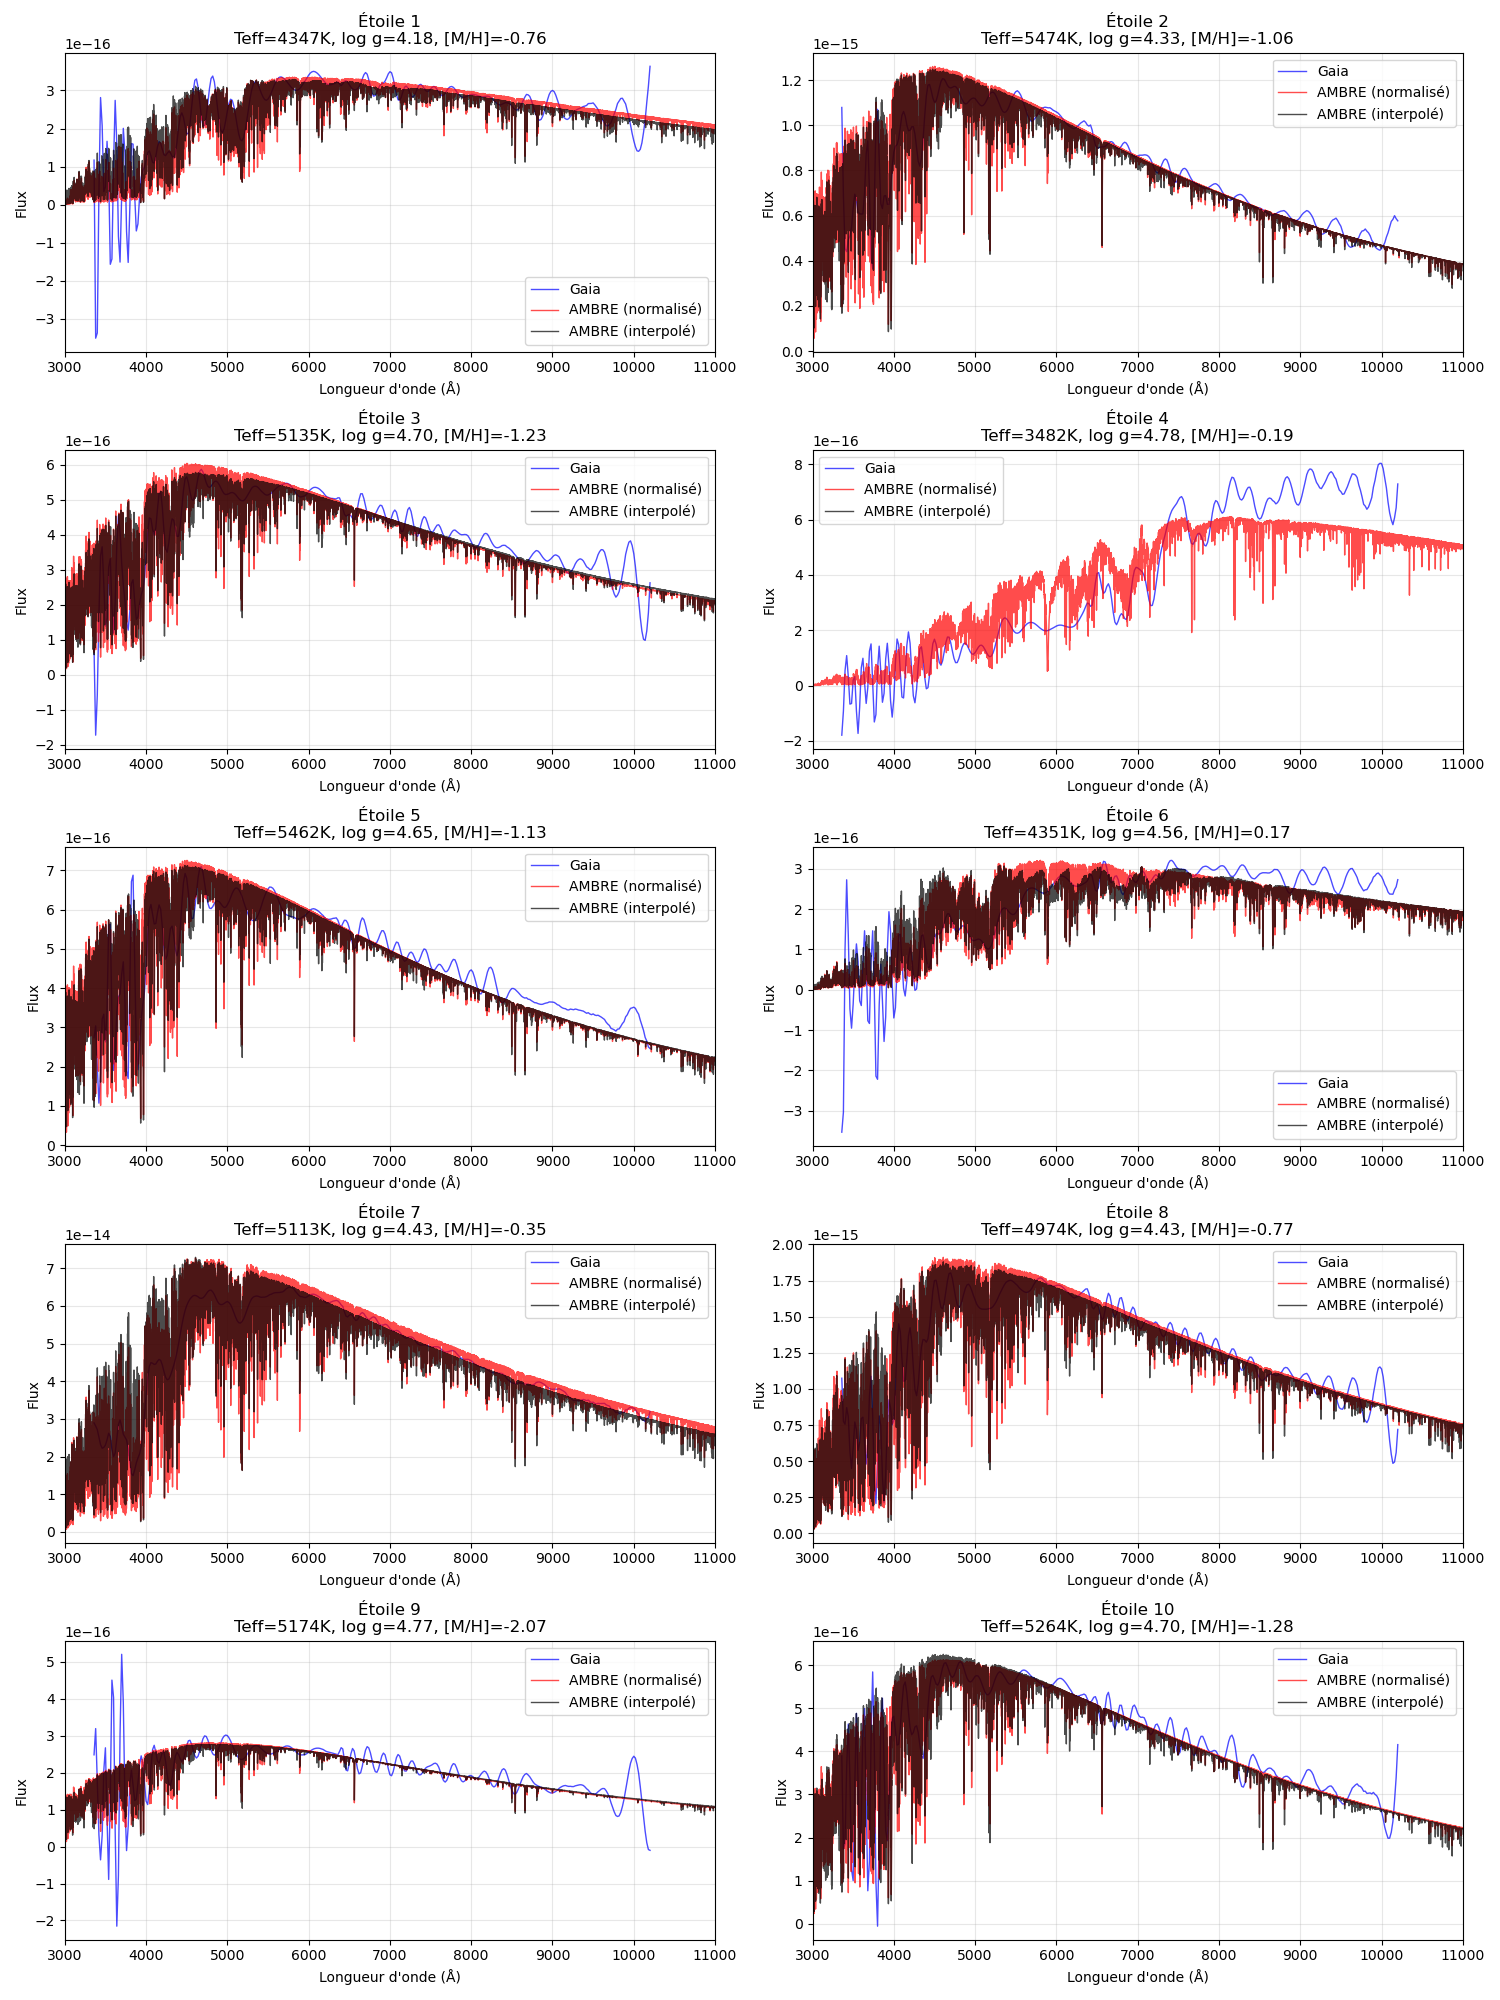

In [17]:
# Traiter les 10 premières étoiles avec paramètres astrophysiques
gaia_with_params = gaia.data.dropna(subset=['teff_gspphot', 'logg_gspphot', 'mh_gspphot'])
first_10_stars = gaia_with_params.head(10)

# Créer les graphiques
fig, axes = plt.subplots(5, 2, figsize=(15, 20))
axes = axes.flatten()

for i, (source_id, star_data) in enumerate(first_10_stars.iterrows()):
    if i >= 10:
        break
        
    # Paramètres stellaires de Gaia
    teff_gaia = star_data['teff_gspphot']
    logg_gaia = star_data['logg_gspphot']
    mh_gaia = star_data['mh_gspphot']
    
    print(f"\nÉtoile {i+1} (source_id: {source_id}):")
    print(f"  Gaia: Teff={teff_gaia:.0f}K, log g={logg_gaia:.2f}, [M/H]={mh_gaia:.2f}")
    
    # Trouver le spectre AMBRE le plus proche
    closest_idx, distance = find_closest_ambre(teff_gaia, logg_gaia, mh_gaia, ambre_complete)
    closest_ambre = ambre_complete.iloc[closest_idx]
   
    print(f"  AMBRE: Teff={closest_ambre['teff']:.0f}K, log g={closest_ambre['logg']:.2f}, [M/H]={closest_ambre['mh']:.2f}")
    print(f"  Distance normalisée: {distance:.3f}")
    print(f"  Fichier: {closest_ambre['filename']}")
    
    # Lire le spectre AMBRE
    ambre_flux = closest_ambre['flux_binned']
    ambre_wave = closest_ambre['wave_binned']
    
    # Version interpolée
    ambre_flux_interp = ambre_spectrum_interpolator(ambre_wave, teff_gaia, logg_gaia, mh_gaia)
    # Tracer les spectres
    ax = axes[i]
    
    # Spectre Gaia
    gaia_flux = star_data['flux']
    ax.plot(gaia.wave, gaia_flux, 'b-', label='Gaia', alpha=0.7, linewidth=1)
    
    # Spectre AMBRE (si lu avec succès)
    if ambre_wave is not None and ambre_flux is not None:
        normalization_factor = ambre_normalization(ambre_wave, ambre_flux, gaia.wave, gaia_flux)
        ambre_flux_norm = ambre_flux * normalization_factor
        ax.plot(ambre_wave, ambre_flux_norm, 'r-', label='AMBRE (normalisé)', alpha=0.7, linewidth=1)
        normalization_factor = ambre_normalization(ambre_wave, ambre_flux_interp, gaia.wave, gaia_flux)
        ambre_flux_norm = ambre_flux_interp * normalization_factor
        ax.plot(ambre_wave, ambre_flux_norm, 'k-', label='AMBRE (interpolé)', alpha=0.7, linewidth=1)

    ax.set_xlabel('Longueur d\'onde (Å)')
    ax.set_ylabel('Flux')
    ax.set_title(f'Étoile {i+1}\nTeff={teff_gaia:.0f}K, log g={logg_gaia:.2f}, [M/H]={mh_gaia:.2f}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim(3000, 11000)

plt.tight_layout()
plt.show()

## Impact in ZTF magnitudes

In [16]:
from lemaitre import bandpasses
from lemaitre.bandpasses.flibs import _ccdid_qid_to_rcid

filt_colors = {
    'ZTF_r': 'r',
    'ZTF_g': 'g',
    'ZTF_i': 'orange',
    'ZTF_empty': 'gray',}

bands = ['ztf1::' + b for b in ['g', 'r', 'i']]
flib = bandpasses.get_filterlib(rebuild=True,atmospheric_model='Palomar')


2025-11-19 16:05:58,358 INFO building lemaitre filterlib with Palomar atmospheric model
2025-11-19 16:06:01,869 INFO saving lemaitre filterlib to /Users/jneveu/Library/Caches/bbf/lemaitre_flib.palomar.5184a9fb97e2b5e0826e509a1afac552f981d6ad03a9ea29c89bee79a0269ac4.pkl


NameError: name 'flib' is not defined

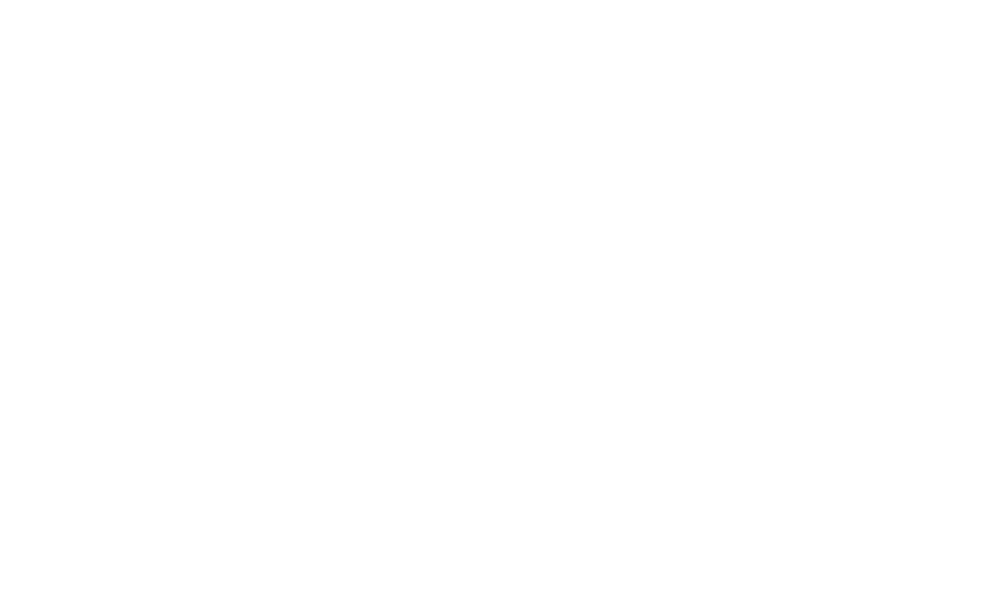

In [18]:
ccdids = [11]
wlA = np.arange(3000., 10989., 10.)
airmass = 1.2
diffs = []

fig = plt.figure(figsize=(10, 6))
for filt in ['g']:  # , 'r', 'i']:
    bp = flib.get(f"ztf1::{filt}")
    for ccdid in ccdids:
        sensor_id = _ccdid_qid_to_rcid(ccdid, 1) + 1
        tr_bbf = bp(x=0, y=0, sensor_id=sensor_id, wl=wlA, airmass=airmass)
        for i in range(5000):
            star_data = gaia.data.iloc[i]
            star = np.interp(wlA, gaia.wave, star_data['flux'], left=0, right=0)
            
            # Paramètres stellaires de Gaia
            teff_gaia = star_data['teff_gspphot']
            logg_gaia = star_data['logg_gspphot']
            mh_gaia = star_data['mh_gspphot']
            if np.isnan(teff_gaia) or np.isnan(logg_gaia) or np.isnan(mh_gaia):
                continue
            
            # Trouver le spectre AMBRE le plus proche
            closest_idx, distance = find_closest_ambre(teff_gaia, logg_gaia, mh_gaia, ambre_complete)
            closest_ambre = ambre_complete.iloc[closest_idx]
            
            if closest_ambre['teff'] == np.max(ambre_complete['teff']) or closest_ambre['teff'] == np.min(ambre_complete['teff']):
                continue
            if closest_ambre['logg'] == np.max(ambre_complete['logg']) or closest_ambre['logg'] == np.min(ambre_complete['logg']):
                continue
            if closest_ambre['mh'] == np.max(ambre_complete['mh']) or closest_ambre['mh'] == np.min(ambre_complete['mh']):
                continue
            
            # Lire le spectre AMBRE
            # ambre_flux = closest_ambre['flux_binned']
            ambre_wave = closest_ambre['wave_binned']
            # ambre_wave = gaia.wave

            # Version interpolée
            ambre_flux = ambre_spectrum_interpolator(ambre_wave, teff_gaia, logg_gaia, mh_gaia)

            # Spectre Gaia
            gaia_flux = star_data['flux']
            wl_mean = np.sum(wlA * tr_bbf * star) / np.sum(tr_bbf * star)
            
            normalization_factor = ambre_normalization(ambre_wave, ambre_flux, gaia.wave, gaia_flux)
            ambre_flux_norm = ambre_flux * normalization_factor

        
            star2 = np.interp(wlA, ambre_wave, ambre_flux_norm, left=0, right=0)
            wl_mean2 = np.sum(wlA * tr_bbf * star2) / np.sum(tr_bbf * star2)
            diffs.append(wl_mean2 - wl_mean)

            if abs(wl_mean2 - wl_mean) > 50:
                print(f"\nÉtoile {i+1} (source_id: {source_id}):")
                print(f"  Gaia: Teff={teff_gaia:.0f}K, log g={logg_gaia:.2f}, [M/H]={mh_gaia:.2f}")
                print(f"  AMBRE: Teff={closest_ambre['teff']:.0f}K, log g={closest_ambre['logg']:.2f}, [M/H]={closest_ambre['mh']:.2f}")
                print(f"  Distance normalisée: {distance:.3f}")
                print(f"  Fichier: {closest_ambre['filename']}")
                print(f"  Grande différence de longueur d'onde moyenne: {wl_mean:.1f} A vs {wl_mean2:.1f} A")
                # p = plt.plot(ambre_wave, ambre_flux_norm, '-', label='AMBRE (normalisé)', alpha=0.7, linewidth=1)
                p = plt.plot(wlA, tr_bbf * star, label=rf'{filt} star {i} $<\lambda>={wl_mean:.1f}\,$A', linestyle=':', lw=2) #, color=p[0].get_color())
                plt.axvline(wl_mean, color=p[0].get_color(), linestyle=':', lw=1)
                plt.plot(wlA, tr_bbf * star2, label=rf'{filt} star {i} $<\lambda>={wl_mean2:.1f}\,$A', color=p[0].get_color(), linestyle='-', lw=2)
                plt.axvline(wl_mean2, color=p[0].get_color(), linestyle='-', lw=1)

#plt.xlim(350, 600)
#plt.legend(fontsize='small', loc='best', ncol=2)
plt.xlabel('Wavelength (A)')
plt.ylabel('Transmission')
plt.xlim(3000, 11000)
#plt.yscale("log")
#plt.ylim(0, 0.8)
plt.grid()
fig.tight_layout()
plt.show()

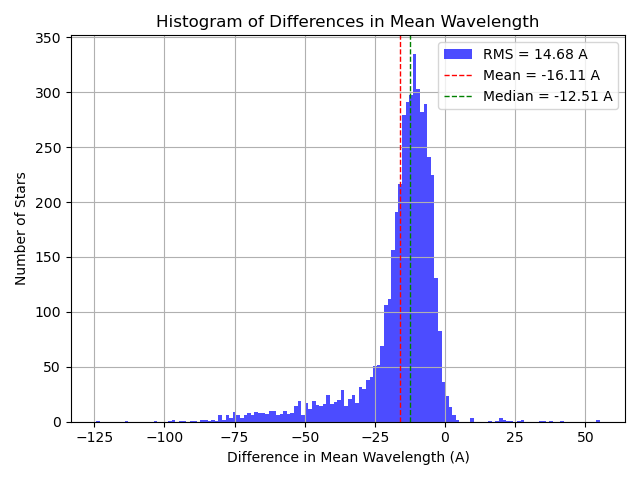

In [18]:

fig = plt.figure()
plt.hist(diffs, bins='fd', color='blue', alpha=0.7, label='RMS = {:.2f} A'.format(np.std(diffs)))
plt.axvline(np.mean(diffs), color='red', linestyle='dashed', linewidth=1, label=f'Mean = {np.mean(diffs):.2f} A')
plt.axvline(np.median(diffs), color='green', linestyle='dashed', linewidth=1, label=f'Median = {np.median(diffs):.2f} A')
plt.legend()
plt.xlabel('Difference in Mean Wavelength (A)')
plt.ylabel('Number of Stars')
plt.title('Histogram of Differences in Mean Wavelength')
plt.grid()
fig.tight_layout()
plt.show()

In [19]:
# Calculer wl_mean et wl_mean2 pour toutes les étoiles de gaia.data
print("Calcul des longueurs d'onde moyennes pour toutes les étoiles...")

from lemaitre import bandpasses
from lemaitre.bandpasses.flibs import _ccdid_qid_to_rcid

# Paramètres de configuration
ccdid = 11
wlA = np.arange(3000., 10989., 10.)
airmass = 1.2
filt = 'g'

# Initialiser le bandpass
flib = bandpasses.get_filterlib(rebuild=True, atmospheric_model='Palomar')
bp = flib.get(f"ztf1::{filt}")
sensor_id = _ccdid_qid_to_rcid(ccdid, 1) + 1
tr_bbf = bp(x=0, y=0, sensor_id=sensor_id, wl=wlA, airmass=airmass)

# Créer des listes pour stocker les résultats
wl_mean_list = []
wl_mean2_list = []
distance_list = []
wl_diff_list = []
has_params_list = []

print(f"Traitement de {len(gaia.data)} étoiles...")

# Boucler sur toutes les étoiles
for i, (source_id, star_data) in enumerate(tqdm(gaia.data.iterrows(), total=len(gaia.data), desc="Calcul longueurs d'onde")):
    
    # Initialiser avec des NaN par défaut
    wl_mean = np.nan
    wl_mean2 = np.nan
    distance = np.nan
    wl_diff = np.nan
    has_params = False
    
    try:
        # Paramètres stellaires de Gaia
        teff_gaia = star_data['teff_gspphot']
        logg_gaia = star_data['logg_gspphot']
        mh_gaia = star_data['mh_gspphot']
        if not np.isnan(star_data['mh_gspspec']):
            mh_gaia = star_data['mh_gspspec']
        
        # Vérifier si les paramètres astrophysiques sont disponibles
        if not (np.isnan(teff_gaia) or np.isnan(logg_gaia) or np.isnan(mh_gaia)):
            has_params = True
            
            # Spectre Gaia interpolé sur la grille wlA
            star = np.interp(wlA, gaia.wave, star_data['flux'], left=0, right=0)
            
            # Calculer wl_mean pour Gaia
            if np.sum(tr_bbf * star) > 0:
                wl_mean = np.sum(wlA * tr_bbf * star) / np.sum(tr_bbf * star)
            
            # Trouver le spectre AMBRE le plus proche
            closest_idx, distance = find_closest_ambre(teff_gaia, logg_gaia, mh_gaia, ambre_complete)
            closest_ambre = ambre_complete.iloc[closest_idx]
            
            # Éviter les paramètres aux limites de la grille
            if (closest_ambre['teff'] != np.max(ambre_complete['teff']) and 
                closest_ambre['teff'] != np.min(ambre_complete['teff']) and
                closest_ambre['logg'] != np.max(ambre_complete['logg']) and 
                closest_ambre['logg'] != np.min(ambre_complete['logg']) and
                closest_ambre['mh'] != np.max(ambre_complete['mh']) and 
                closest_ambre['mh'] != np.min(ambre_complete['mh']) and
                teff_gaia > np.min(ambre_complete['teff']) and teff_gaia < np.max(ambre_complete['teff']) and
                logg_gaia > np.min(ambre_complete['logg']) and logg_gaia < np.max(ambre_complete['logg']) and
                mh_gaia > np.min(ambre_complete['mh']) and mh_gaia < np.max(ambre_complete['mh'])):
                
                # Grille de longueurs d'onde AMBRE
                ambre_wave = closest_ambre['wave_binned']
                
                # Version interpolée
                ambre_flux = ambre_spectrum_interpolator(ambre_wave, teff_gaia, logg_gaia, mh_gaia)
                ambre_flux = closest_ambre['flux_binned']
                # ambre_flux = ambre_knn_spectrum_interpolator(knn_model, ambre_wave, teff_gaia, logg_gaia, mh_gaia)
                
                # Vérifier si l'interpolation a réussi (pas tout NaN)
                if not np.all(np.isnan(ambre_flux)):
                    # Normaliser le spectre AMBRE
                    normalization_factor = ambre_normalization(ambre_wave, ambre_flux, gaia.wave, star_data['flux'])
                    ambre_flux_norm = ambre_flux * normalization_factor
                    
                    # Interpoler sur la grille wlA
                    star2 = np.interp(wlA, ambre_wave, ambre_flux_norm, left=0, right=0)
                    
                    # Calculer wl_mean2 pour AMBRE
                    if np.sum(tr_bbf * star2) > 0:
                        wl_mean2 = np.sum(wlA * tr_bbf * star2) / np.sum(tr_bbf * star2)
                        
                        # Calculer la différence
                        if not np.isnan(wl_mean) and not np.isnan(wl_mean2):
                            wl_diff = wl_mean2 - wl_mean
                
    except Exception as e:
        # En cas d'erreur, garder les valeurs NaN par défaut
        if i < 10:  # Afficher seulement les 10 premières erreurs
            print(f"Erreur pour étoile {i} (source_id: {source_id}): {e}")
    
    # Ajouter aux listes
    wl_mean_list.append(wl_mean)
    wl_mean2_list.append(wl_mean2)
    distance_list.append(distance)
    wl_diff_list.append(wl_diff)
    has_params_list.append(has_params)

# Ajouter les nouvelles colonnes au DataFrame
print("\nAjout des nouvelles colonnes au DataFrame...")
gaia.data['wl_mean_gaia'] = wl_mean_list
gaia.data['wl_mean_ambre'] = wl_mean2_list
gaia.data['ambre_distance'] = distance_list
gaia.data['wl_diff'] = wl_diff_list
gaia.data['has_astro_params'] = has_params_list

# Statistiques
valid_wl_mean = np.sum(~np.isnan(gaia.data['wl_mean_gaia']))
valid_wl_mean2 = np.sum(~np.isnan(gaia.data['wl_mean_ambre']))
valid_diff = np.sum(~np.isnan(gaia.data['wl_diff']))
stars_with_params = np.sum(gaia.data['has_astro_params'])

print(f"\n=== RÉSUMÉ ===")
print(f"Total étoiles : {len(gaia.data)}")
print(f"Étoiles avec paramètres astrophysiques : {stars_with_params}")
print(f"wl_mean_gaia valides : {valid_wl_mean}")
print(f"wl_mean_ambre valides : {valid_wl_mean2}")
print(f"Différences valides : {valid_diff}")

if valid_diff > 0:
    wl_diff_clean = gaia.data['wl_diff'].dropna()
    print(f"\n=== STATISTIQUES DES DIFFÉRENCES ===")
    print(f"Moyenne : {np.mean(wl_diff_clean):.2f} Å")
    print(f"Médiane : {np.median(wl_diff_clean):.2f} Å")
    print(f"Écart-type : {np.std(wl_diff_clean):.2f} Å")
    print(f"Min : {np.min(wl_diff_clean):.2f} Å")
    print(f"Max : {np.max(wl_diff_clean):.2f} Å")

# Afficher les premières lignes avec les nouvelles colonnes
print(f"\n=== PREMIÈRES LIGNES AVEC NOUVELLES COLONNES ===")
display_cols = ['wl_mean_gaia', 'wl_mean_ambre', 'wl_diff', 'ambre_distance', 'has_astro_params']
print(gaia.data[display_cols].head(10))

# Sauvegarder le DataFrame enrichi
print(f"\nSauvegarde du DataFrame enrichi...")
gaia.data.to_parquet("gaia_data_with_wavelengths.parquet")
print("Sauvegardé dans gaia_data_with_wavelengths.parquet")

2025-11-19 16:06:13,338 INFO building lemaitre filterlib with Palomar atmospheric model


Calcul des longueurs d'onde moyennes pour toutes les étoiles...


2025-11-19 16:06:16,431 INFO saving lemaitre filterlib to /Users/jneveu/Library/Caches/bbf/lemaitre_flib.palomar.5184a9fb97e2b5e0826e509a1afac552f981d6ad03a9ea29c89bee79a0269ac4.pkl


Traitement de 158493 étoiles...


Calcul longueurs d'onde: 100%|██████████| 158493/158493 [04:53<00:00, 539.32it/s]



Ajout des nouvelles colonnes au DataFrame...

=== RÉSUMÉ ===
Total étoiles : 158493
Étoiles avec paramètres astrophysiques : 142085
wl_mean_gaia valides : 142085
wl_mean_ambre valides : 137006
Différences valides : 137006

=== STATISTIQUES DES DIFFÉRENCES ===
Moyenne : -6.08 Å
Médiane : -4.20 Å
Écart-type : 10.28 Å
Min : -157.68 Å
Max : 130.95 Å

=== PREMIÈRES LIGNES AVEC NOUVELLES COLONNES ===
                     wl_mean_gaia  wl_mean_ambre    wl_diff  ambre_distance  \
1201049160076424448   4872.493474    4871.403206  -1.090268        0.039658   
1201049228795888896   4824.825797    4820.156392  -4.669405        0.033067   
1201051221660722816   4834.014764    4829.730325  -4.284439        0.058953   
1201051496538672256   4943.659924            NaN        NaN        0.041359   
1201051908855488000   4824.866407    4820.156392  -4.710015        0.035745   
1201052011934702720   4908.022315    4883.726011 -24.296304        0.028597   
1201052149373654400   4845.349491    4854.681103

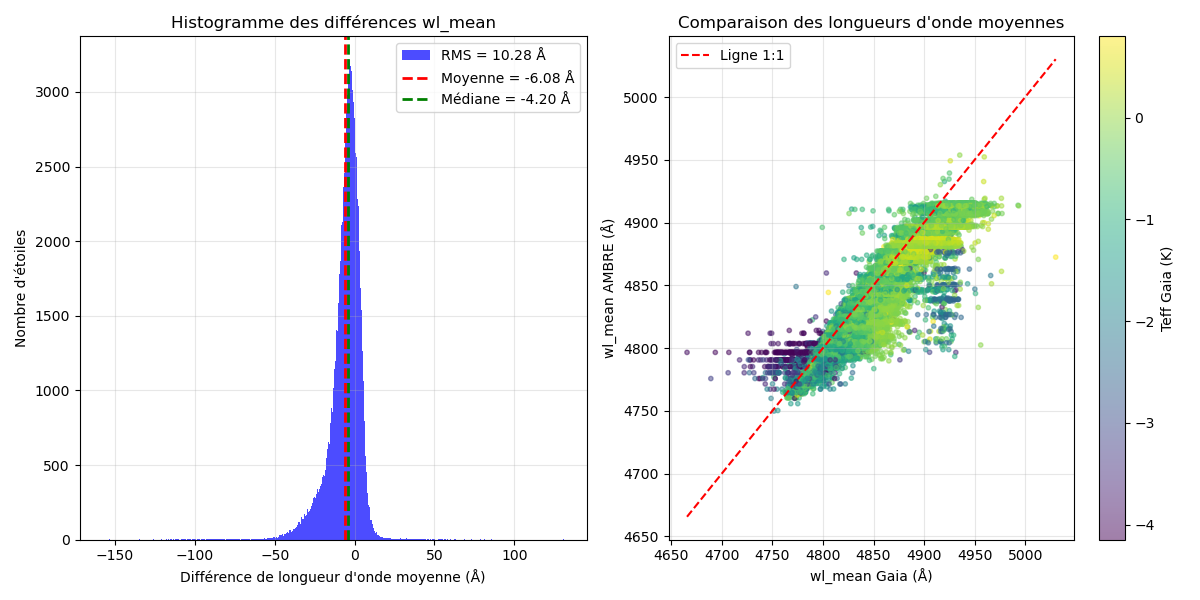

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Histogramme des différences
wl_diff_clean = gaia.data['wl_diff'].dropna()
ax1.hist(wl_diff_clean, bins='fd', color='blue', alpha=0.7, 
            label=f'RMS = {np.std(wl_diff_clean):.2f} Å')
ax1.axvline(np.mean(wl_diff_clean), color='red', linestyle='dashed', 
            linewidth=2, label=f'Moyenne = {np.mean(wl_diff_clean):.2f} Å')
ax1.axvline(np.median(wl_diff_clean), color='green', linestyle='dashed', 
            linewidth=2, label=f'Médiane = {np.median(wl_diff_clean):.2f} Å')
ax1.set_xlabel('Différence de longueur d\'onde moyenne (Å)')
ax1.set_ylabel('Nombre d\'étoiles')
ax1.set_title('Histogramme des différences wl_mean')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Scatter plot wl_mean_gaia vs wl_mean_ambre
valid_both = gaia.data.dropna(subset=['wl_mean_gaia', 'wl_mean_ambre'])
sc = ax2.scatter(valid_both['wl_mean_gaia'], valid_both['wl_mean_ambre'], 
            alpha=0.5, s=10, c=valid_both['mh_gspphot'], cmap='viridis')
ax2.plot([valid_both['wl_mean_gaia'].min(), valid_both['wl_mean_gaia'].max()],
            [valid_both['wl_mean_gaia'].min(), valid_both['wl_mean_gaia'].max()],
            'r--', label='Ligne 1:1')
plt.colorbar(sc, ax=ax2, label='Teff Gaia (K)')
ax2.set_xlabel('wl_mean Gaia (Å)')
ax2.set_ylabel('wl_mean AMBRE (Å)')
ax2.set_title('Comparaison des longueurs d\'onde moyennes')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== ANALYSE DES CORRÉLATIONS AVEC LES PARAMÈTRES ASTROPHYSIQUES ===
Nombre d'étoiles avec wl_diff valide : 137006


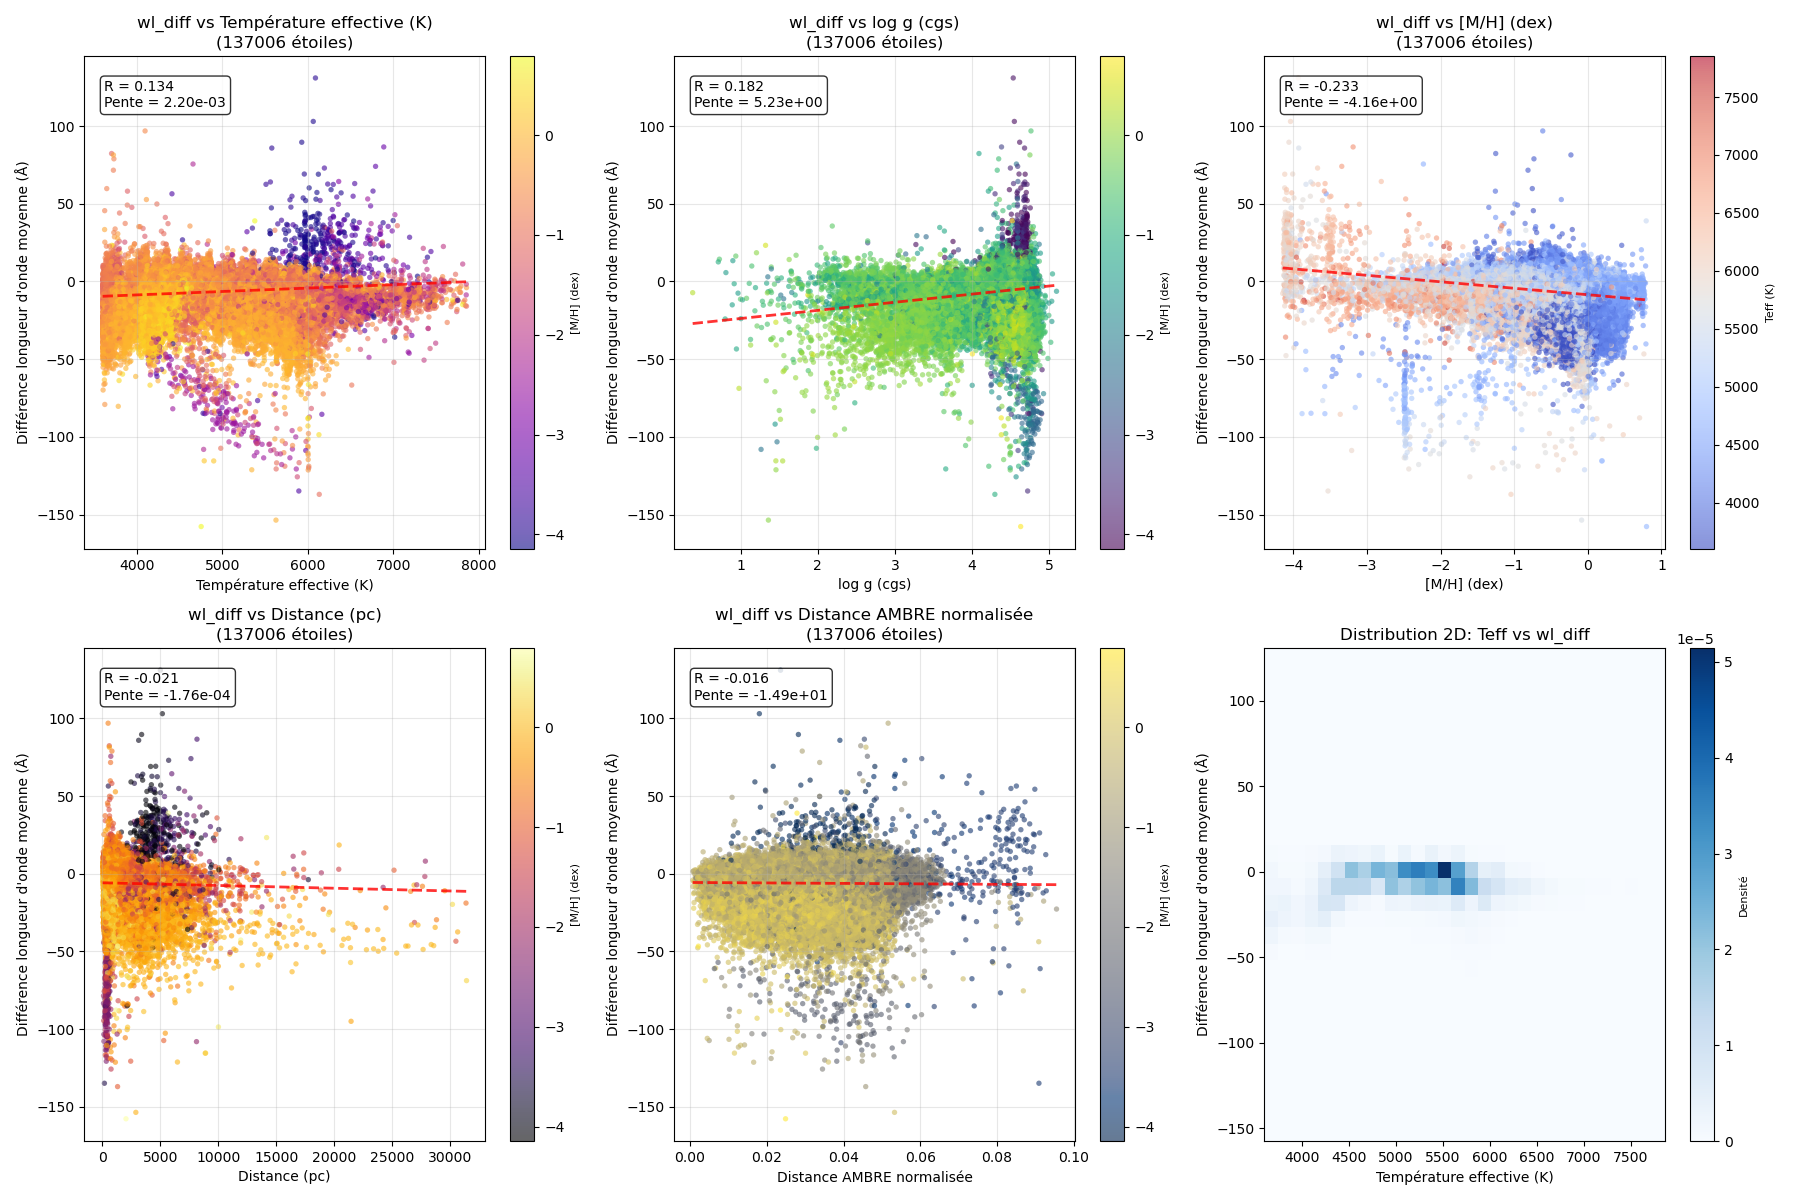


=== COEFFICIENTS DE CORRÉLATION ===
Paramètre                 Corrélation (R) Force       
----------------------------------------------------
mh_gspphot                 -0.233        Faible      
logg_gspphot               +0.182        Faible      
teff_gspphot               +0.134        Faible      
distance_gspphot           -0.021        Très faible 
ambre_distance             -0.016        Très faible 

Corrélation la plus forte: mh_gspphot (R = -0.233)

=== STATISTIQUES SUPPLÉMENTAIRES ===
Nombre de paramètres analysés: 5
Corrélations fortes (|R| > 0.5): 0
Corrélations modérées (0.3 < |R| ≤ 0.5): 0
Corrélations faibles (0.1 < |R| ≤ 0.3): 3

=== ANALYSE PAR TYPE STELLAIRE ===
Type stellaire  Nombre   wl_diff moyen (Å)  σ (Å)     
------------------------------------------------------------
M (< 4000K)     5552         -19.80         14.22
K (4000-5200K)  58892         -5.52          9.98
G (5200-6000K)  63368         -4.99          8.95
F (6000-7500K)  9130          -8.93     

In [21]:
# Analyse des corrélations entre wl_diff et les paramètres astrophysiques
print("=== ANALYSE DES CORRÉLATIONS AVEC LES PARAMÈTRES ASTROPHYSIQUES ===")

# Filtrer les données valides pour l'analyse
valid_data = gaia.data.dropna(subset=['wl_diff'])
print(f"Nombre d'étoiles avec wl_diff valide : {len(valid_data)}")

if len(valid_data) < 10:
    print("Pas assez de données pour l'analyse des corrélations")
else:
    # Créer une grille de sous-graphiques
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    
    # Définir les paramètres à analyser
    params_info = [
        ('teff_gspphot', 'Température effective (K)', 'plasma'),
        ('logg_gspphot', 'log g (cgs)', 'viridis'),
        ('mh_gspphot', '[M/H] (dex)', 'coolwarm'),
        ('distance_gspphot', 'Distance (pc)', 'inferno'),
        ('ambre_distance', 'Distance AMBRE normalisée', 'cividis')
    ]
    
    correlations = {}
    
    # Créer les scatter plots
    for i, (param, label, cmap) in enumerate(params_info):
        ax = axes[i]
        
        if param in valid_data.columns:
            # Filtrer les données pour ce paramètre
            param_data = valid_data.dropna(subset=[param])
            
            if len(param_data) > 10:
                # Créer le scatter plot
                if param == 'mh_gspphot':
                    # Pour [M/H], utiliser Teff comme couleur
                    color_param = param_data['teff_gspphot'] if 'teff_gspphot' in param_data.columns else param_data[param]
                    color_label = 'Teff (K)'
                else:
                    # Pour les autres paramètres, utiliser [M/H] comme couleur si disponible
                    color_param = param_data['mh_gspphot'] if 'mh_gspphot' in param_data.columns else param_data[param]
                    color_label = '[M/H] (dex)' if 'mh_gspphot' in param_data.columns else label
                
                scatter = ax.scatter(param_data[param], param_data['wl_diff'], 
                                   c=color_param, cmap=cmap, 
                                   alpha=0.6, s=15, edgecolors='none')
                
                # Ajouter une ligne de tendance
                try:
                    # Calculer la régression linéaire
                    mask_finite = np.isfinite(param_data[param]) & np.isfinite(param_data['wl_diff'])
                    if np.sum(mask_finite) > 5:
                        x_clean = param_data[param][mask_finite]
                        y_clean = param_data['wl_diff'][mask_finite]
                        
                        z = np.polyfit(x_clean, y_clean, 1)
                        p = np.poly1d(z)
                        
                        # Tracer la ligne de tendance
                        x_trend = np.linspace(x_clean.min(), x_clean.max(), 100)
                        ax.plot(x_trend, p(x_trend), "r--", alpha=0.8, linewidth=2)
                        
                        # Calculer le coefficient de corrélation
                        corr = np.corrcoef(x_clean, y_clean)[0,1]
                        correlations[param] = corr
                        
                        # Afficher R et la pente
                        slope = z[0]
                        ax.text(0.05, 0.95, f'R = {corr:.3f}\nPente = {slope:.2e}', 
                               transform=ax.transAxes, 
                               bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
                               verticalalignment='top')
                except Exception as e:
                    print(f"Erreur calcul tendance pour {param}: {e}")
                
                ax.set_xlabel(label)
                ax.set_ylabel('Différence longueur d\'onde moyenne (Å)')
                ax.set_title(f'wl_diff vs {label}\n({len(param_data)} étoiles)')
                ax.grid(True, alpha=0.3)
                
                # Colorbar
                cbar = plt.colorbar(scatter, ax=ax)
                cbar.set_label(color_label, fontsize=8)
                
            else:
                ax.text(0.5, 0.5, f'Données insuffisantes\npour {param}\n({len(param_data)} points)', 
                       ha='center', va='center', transform=ax.transAxes,
                       bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.5))
                ax.set_title(f'wl_diff vs {label}')
        else:
            ax.text(0.5, 0.5, f'Paramètre {param}\nnon disponible', 
                   ha='center', va='center', transform=ax.transAxes,
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="lightcoral", alpha=0.5))
            ax.set_title(f'wl_diff vs {label}')
    
    # Histogramme 2D dans le dernier subplot
    ax = axes[5]
    if 'teff_gspphot' in valid_data.columns:
        teff_data = valid_data.dropna(subset=['teff_gspphot'])
        if len(teff_data) > 50:
            # Créer l'histogramme 2D
            h = ax.hist2d(teff_data['teff_gspphot'], teff_data['wl_diff'], 
                         bins=30, cmap='Blues', density=True)
            ax.set_xlabel('Température effective (K)')
            ax.set_ylabel('Différence longueur d\'onde moyenne (Å)')
            ax.set_title('Distribution 2D: Teff vs wl_diff')
            
            # Colorbar pour l'histogramme 2D
            cbar = plt.colorbar(h[3], ax=ax)
            cbar.set_label('Densité', fontsize=8)
        else:
            ax.text(0.5, 0.5, 'Pas assez de données\npour histogramme 2D', 
                   ha='center', va='center', transform=ax.transAxes)
    
    plt.tight_layout()
    plt.show()
    
    # Afficher le tableau des corrélations
    print(f"\n=== COEFFICIENTS DE CORRÉLATION ===")
    if correlations:
        # Trier par valeur absolue de corrélation
        sorted_corr = sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True)
        
        print(f"{'Paramètre':<25} {'Corrélation (R)':<15} {'Force':<12}")
        print("-" * 52)
        
        for param, corr in sorted_corr:
            if abs(corr) > 0.5:
                force = "Forte"
            elif abs(corr) > 0.3:
                force = "Modérée"
            elif abs(corr) > 0.1:
                force = "Faible"
            else:
                force = "Très faible"
            
            print(f"{param:<25} {corr:>+7.3f}        {force:<12}")
        
        # Identifier la corrélation la plus forte
        strongest = max(correlations.items(), key=lambda x: abs(x[1]))
        print(f"\nCorrélation la plus forte: {strongest[0]} (R = {strongest[1]:+.3f})")
        
        # Statistiques supplémentaires
        print(f"\n=== STATISTIQUES SUPPLÉMENTAIRES ===")
        print(f"Nombre de paramètres analysés: {len(correlations)}")
        print(f"Corrélations fortes (|R| > 0.5): {sum(1 for r in correlations.values() if abs(r) > 0.5)}")
        print(f"Corrélations modérées (0.3 < |R| ≤ 0.5): {sum(1 for r in correlations.values() if 0.3 < abs(r) <= 0.5)}")
        print(f"Corrélations faibles (0.1 < |R| ≤ 0.3): {sum(1 for r in correlations.values() if 0.1 < abs(r) <= 0.3)}")
    else:
        print("Aucune corrélation calculée")
    
    # Analyse par type stellaire
    print(f"\n=== ANALYSE PAR TYPE STELLAIRE ===")
    if 'teff_gspphot' in valid_data.columns:
        teff_valid = valid_data.dropna(subset=['teff_gspphot'])
        
        if len(teff_valid) > 0:
            # Classifier les étoiles par température
            conditions = [
                (teff_valid['teff_gspphot'] < 4000),
                (teff_valid['teff_gspphot'] >= 4000) & (teff_valid['teff_gspphot'] < 5200),
                (teff_valid['teff_gspphot'] >= 5200) & (teff_valid['teff_gspphot'] < 6000),
                (teff_valid['teff_gspphot'] >= 6000) & (teff_valid['teff_gspphot'] < 7500),
                (teff_valid['teff_gspphot'] >= 7500)
            ]
            
            choices = ['M (< 4000K)', 'K (4000-5200K)', 'G (5200-6000K)', 'F (6000-7500K)', 'A (> 7500K)']
            
            teff_valid['stellar_type'] = np.select(conditions, choices, default='Inconnu')
            
            print(f"{'Type stellaire':<15} {'Nombre':<8} {'wl_diff moyen (Å)':<18} {'σ (Å)':<10}")
            print("-" * 60)
            
            for stellar_type in ['M (< 4000K)', 'K (4000-5200K)', 'G (5200-6000K)', 'F (6000-7500K)', 'A (> 7500K)']:
                subset = teff_valid[teff_valid['stellar_type'] == stellar_type]
                if len(subset) > 0:
                    mean_diff = np.mean(subset['wl_diff'])
                    std_diff = np.std(subset['wl_diff'])
                    print(f"{stellar_type:<15} {len(subset):<8} {mean_diff:>+10.2f}        {std_diff:>6.2f}")

print("\n=== ANALYSE TERMINÉE ===")

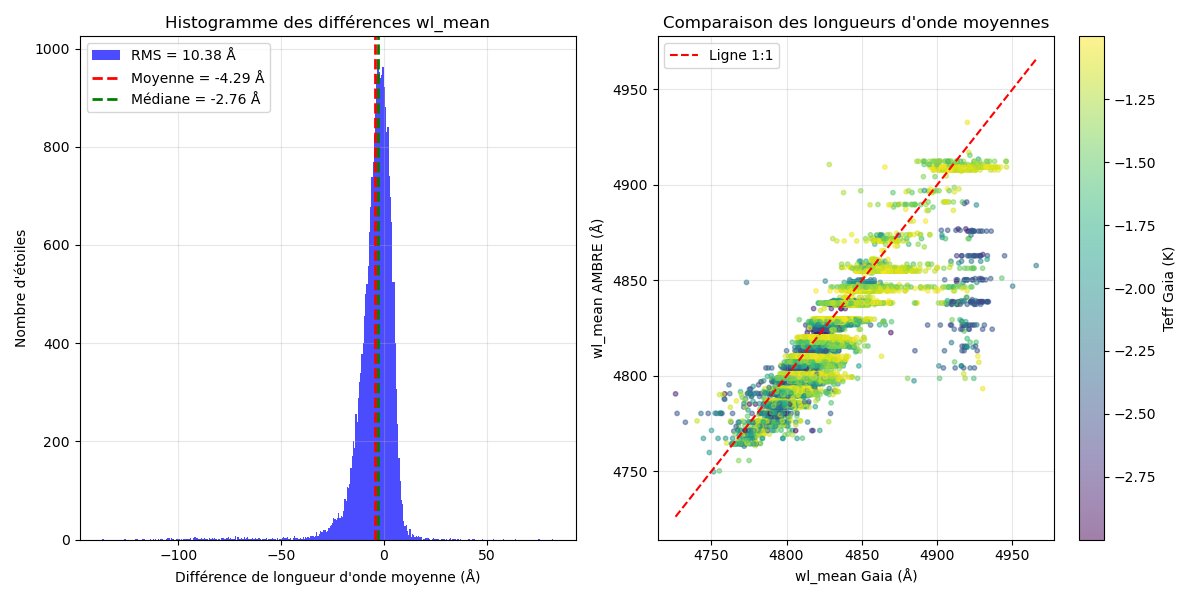

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Histogramme des différences
indices = (gaia.data["mh_gspphot"] > -3) & (gaia.data["mh_gspphot"] < -1)# & (gaia.data["logg_gspphot"] < 4.0)
wl_diff_clean = gaia.data['wl_diff'][indices].dropna()
ax1.hist(wl_diff_clean, bins='fd', color='blue', alpha=0.7, 
            label=f'RMS = {np.std(wl_diff_clean):.2f} Å')
ax1.axvline(np.mean(wl_diff_clean), color='red', linestyle='dashed', 
            linewidth=2, label=f'Moyenne = {np.mean(wl_diff_clean):.2f} Å')
ax1.axvline(np.median(wl_diff_clean), color='green', linestyle='dashed', 
            linewidth=2, label=f'Médiane = {np.median(wl_diff_clean):.2f} Å')
ax1.set_xlabel('Différence de longueur d\'onde moyenne (Å)')
ax1.set_ylabel('Nombre d\'étoiles')
ax1.set_title('Histogramme des différences wl_mean')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Scatter plot wl_mean_gaia vs wl_mean_ambre
valid_both = gaia.data[indices].dropna(subset=['wl_mean_gaia', 'wl_mean_ambre'])
sc = ax2.scatter(valid_both['wl_mean_gaia'], valid_both['wl_mean_ambre'], 
            alpha=0.5, s=10, c=valid_both['mh_gspphot'], cmap='viridis')
ax2.plot([valid_both['wl_mean_gaia'].min(), valid_both['wl_mean_gaia'].max()],
            [valid_both['wl_mean_gaia'].min(), valid_both['wl_mean_gaia'].max()],
            'r--', label='Ligne 1:1')
plt.colorbar(sc, ax=ax2, label='Teff Gaia (K)')
ax2.set_xlabel('wl_mean Gaia (Å)')
ax2.set_ylabel('wl_mean AMBRE (Å)')
ax2.set_title('Comparaison des longueurs d\'onde moyennes')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## SNLS Gaia star library

In [19]:
snls = pd.read_parquet("stars_snls_ztf.parquet")
snls.set_index("source_id", inplace=True)
snls

,ra,dec
source_id,,
2490024748898728704,36.182182,-4.148203
2489559238868085504,36.060555,-4.839345
2488798965232408064,36.437859,-4.900626
2489159295808666752,36.794621,-4.926629
2489553848684372736,36.312206,-4.830714
...,...,...
1608044830889447424,215.087433,53.126709
1608024730442482688,214.603226,52.974136
1607943778898968960,214.988846,52.283394


In [20]:
from gaiaxpy import calibrate

df_spectrum, wls = calibrate(snls.index.to_list(), truncation=False, save_file=False)
print(wls)
print(df_spectrum)


"Important:  Gaia archive will be intermittently  unavailable due to scheduled maintenance until 2-12-2025 12:00 (CET)"
"Important:  Gaia archive will be intermittently  unavailable due to scheduled maintenance until 2-12-2025 12:00 (CET)"


KeyboardInterrupt: 

In [ ]:
np.all(gaia.wave == wls*10)

np.True_

In [ ]:
df_spectrum.set_index("source_id", inplace=True)

In [ ]:
# Incorporer la table astro dans gaia.data en gardant les index originaux
snls = snls.merge(df_spectrum, left_index=True, right_index=True, how='left')
snls

,ra,dec,flux,flux_error
source_id,,,,
2490024748898728704,36.182182,-4.148203,"[7.215320643506566e-18, 1.3147381219780032e-17...","[4.565660451547258e-18, 3.2045753640837637e-18..."
2489559238868085504,36.060555,-4.839345,"[3.2069114619998245e-18, 2.466487597646308e-18...","[2.6995093045952566e-18, 1.9465062342201973e-1..."
2488798965232408064,36.437859,-4.900626,"[1.538764442054766e-18, -3.7032385237877703e-1...","[3.2084135511607483e-18, 2.282968315990342e-18..."
2489159295808666752,36.794621,-4.926629,"[1.0151994507560215e-18, 1.7752598417220412e-1...","[3.578893426478951e-18, 2.564522883533402e-18,..."
2489553848684372736,36.312206,-4.830714,"[1.3183178389148303e-19, 2.4140970131889555e-1...","[3.1011318791017043e-18, 2.2262507866111506e-1..."
...,...,...,...,...
1608044830889447424,215.087433,53.126709,"[1.546772526826251e-17, 1.0628702318615835e-17...","[2.7847356091155207e-18, 2.075685809271014e-18..."
1608024730442482688,214.603226,52.974136,"[2.868597582222788e-17, 2.5724700478109422e-17...","[3.1593200499702335e-18, 2.4198304861480965e-1..."
1607943778898968960,214.988846,52.283394,"[2.1732738678895135e-17, 1.730368717629126e-17...","[4.1883623633736305e-18, 3.0419157857645487e-1..."


In [ ]:
# Traitement par batch de 1000 IDs pour éviter les limites de requête
batch_size = 1000
all_astro_data = []

total_ids = len(snls.index)
print(f"Traitement de {total_ids} IDs par batch de {batch_size}...")

for i in range(0, total_ids, batch_size):
    # Créer le batch d'IDs
    end_idx = min(i + batch_size, total_ids)
    batch_ids = snls.index.values[i:end_idx]
    
    # Convertir en string pour la requête SQL
    gaia_ids_batch = np.array2string(batch_ids, separator=',', max_line_width=np.inf)[1:-1]
    gaia_ids_batch = gaia_ids_batch.replace('\n ', '')
    
    print(f"Traitement du batch {i//batch_size + 1}/{(total_ids-1)//batch_size + 1} ({len(batch_ids)} IDs)")
    
    # Requête Gaia pour ce batch
    qry = f"SELECT source_id,distance_gspphot,teff_gspphot,logg_gspphot,mh_gspphot,teff_gspspec,logg_gspspec,mh_gspspec FROM gaiadr3.astrophysical_parameters gs WHERE gs.source_id in ({gaia_ids_batch});"
    
    try:
        job = Gaia.launch_job(qry)
        batch_astro = job.get_results().to_pandas()
        
        if len(batch_astro) > 0:
            batch_astro.set_index('source_id', inplace=True)
            all_astro_data.append(batch_astro)
            print(f"  -> {len(batch_astro)} résultats trouvés")
        else:
            print(f"  -> Aucun résultat trouvé")
            
    except Exception as e:
        print(f"  -> Erreur lors de la requête: {e}")
        continue

# Fusionner tous les résultats
if all_astro_data:
    astro_snls = pd.concat(all_astro_data, ignore_index=False)
    print(f"\nTotal final: {len(astro_snls)} étoiles avec paramètres astrophysiques")
else:
    print("\nAucune donnée astrophysique récupérée")
    astro_snls = pd.DataFrame()
astro_snls.head()

Traitement de 1098 IDs par batch de 1000...
Traitement du batch 1/2 (1000 IDs)
  -> 1000 résultats trouvés
Traitement du batch 2/2 (98 IDs)
  -> 98 résultats trouvés

Total final: 1098 étoiles avec paramètres astrophysiques


,distance_gspphot,teff_gspphot,logg_gspphot,mh_gspphot,teff_gspspec,logg_gspspec,mh_gspspec
source_id,,,,,,,
1604934346854408832,1203.109985,5122.502441,4.7855,-2.2191,NaN,NaN,NaN
1604934484293363328,1082.393555,5479.066895,4.4722,-0.1850,NaN,NaN,NaN
1607850457850514176,926.295227,4623.423828,4.6011,0.0897,NaN,NaN,NaN
1607853309708797440,2496.358398,5413.897461,4.3354,-3.2927,NaN,NaN,NaN
1607853550226966400,879.418823,4202.876465,4.6571,-0.0052,NaN,NaN,NaN


In [ ]:
# Incorporer la table astro dans gaia.data en gardant les index originaux
snls = snls.merge(astro_snls, left_index=True, right_index=True, how='left')

# Vérifier le résultat
print(f"Nombre de lignes après fusion : {len(snls)}")
# print(f"Colonnes ajoutées : {['teff_gspphot', 'logg_gspphot', 'mh_gspphot']}")
print(f"Index conservé : {snls.index.name}")
print(f"Nombre d'étoiles avec paramètres astrophysiques : {np.sum(~np.isnan(snls['teff_gspphot']))}")
print("\nPremières lignes du DataFrame fusionné :")
snls.head()

Nombre de lignes après fusion : 1098
Index conservé : source_id
Nombre d'étoiles avec paramètres astrophysiques : 1052

Premières lignes du DataFrame fusionné :


,ra,dec,flux,flux_error,distance_gspphot,teff_gspphot,logg_gspphot,mh_gspphot,teff_gspspec,logg_gspspec,mh_gspspec
source_id,,,,,,,,,,,
2490024748898728704,36.182182,-4.148203,"[7.215320643506566e-18, 1.3147381219780032e-17...","[4.565660451547258e-18, 3.2045753640837637e-18...",560.585327,4746.301758,4.5544,-0.1438,NaN,NaN,NaN
2489559238868085504,36.060555,-4.839345,"[3.2069114619998245e-18, 2.466487597646308e-18...","[2.6995093045952566e-18, 1.9465062342201973e-1...",938.503113,4483.860352,4.6588,-0.0309,NaN,NaN,NaN
2488798965232408064,36.437859,-4.900626,"[1.538764442054766e-18, -3.7032385237877703e-1...","[3.2084135511607483e-18, 2.282968315990342e-18...",1558.070557,5269.140137,4.4634,-0.4278,NaN,NaN,NaN
2489159295808666752,36.794621,-4.926629,"[1.0151994507560215e-18, 1.7752598417220412e-1...","[3.578893426478951e-18, 2.564522883533402e-18,...",121.322304,3176.096924,4.9635,0.0021,NaN,NaN,NaN
2489553848684372736,36.312206,-4.830714,"[1.3183178389148303e-19, 2.4140970131889555e-1...","[3.1011318791017043e-18, 2.2262507866111506e-1...",441.188995,3584.143799,4.7575,0.0070,NaN,NaN,NaN


In [ ]:

from lemaitre import bandpasses
from lemaitre.bandpasses.flibs import _ccdid_qid_to_rcid


# Calculer wl_mean et wl_mean2 pour toutes les étoiles de gaia.data
print("Calcul des longueurs d'onde moyennes pour toutes les étoiles...")

# Paramètres de configuration
ccdid = 11
wlA = np.arange(3000., 10989., 10.)
airmass = 1.2
filt = 'g'

# Initialiser le bandpass
flib = bandpasses.get_filterlib(rebuild=True, atmospheric_model='Palomar')
bp = flib.get(f"ztf1::{filt}")
sensor_id = _ccdid_qid_to_rcid(ccdid, 1) + 1
tr_bbf = bp(x=0, y=0, sensor_id=sensor_id, wl=wlA, airmass=airmass)

# Créer des listes pour stocker les résultats
wl_mean_list = []
wl_mean2_list = []
distance_list = []
wl_diff_list = []
has_params_list = []

print(f"Traitement de {len(snls)} étoiles...")

snls['synth_flux'] = None
snls['synth_wave'] = None
snls['synth_flux'] = snls['synth_flux'].astype('object')
snls['synth_wave'] = snls['synth_wave'].astype('object')


# Boucler sur toutes les étoiles
for i, (source_id, star_data) in enumerate(tqdm(snls.iterrows(), total=len(snls), desc="Calcul longueurs d'onde")):
    
    # Initialiser avec des NaN par défaut
    wl_mean = np.nan
    wl_mean2 = np.nan
    distance = np.nan
    wl_diff = np.nan
    has_params = False
    
    try:
        # Paramètres stellaires de Gaia
        teff_gaia = star_data['teff_gspphot']
        logg_gaia = star_data['logg_gspphot']
        mh_gaia = star_data['mh_gspphot']
        if not np.isnan(star_data['mh_gspspec']):
            mh_gaia = star_data['mh_gspspec']
        
        # Vérifier si les paramètres astrophysiques sont disponibles
        if not (np.isnan(teff_gaia) or np.isnan(logg_gaia) or np.isnan(mh_gaia)):
            has_params = True
            
            # Spectre Gaia interpolé sur la grille wlA
            star = np.interp(wlA, gaia.wave, star_data['flux'], left=0, right=0)
            
            # Calculer wl_mean pour Gaia
            if np.sum(tr_bbf * star) > 0:
                wl_mean = np.sum(wlA * tr_bbf * star) / np.sum(tr_bbf * star)
            
            # Trouver le spectre AMBRE le plus proche
            closest_idx, distance = find_closest_ambre(teff_gaia, logg_gaia, mh_gaia, ambre_complete)
            closest_ambre = ambre_complete.iloc[closest_idx]
            
            # Éviter les paramètres aux limites de la grille
            if (closest_ambre['teff'] != np.max(ambre_complete['teff']) and 
                closest_ambre['teff'] != np.min(ambre_complete['teff']) and
                closest_ambre['logg'] != np.max(ambre_complete['logg']) and 
                closest_ambre['logg'] != np.min(ambre_complete['logg']) and
                closest_ambre['mh'] != np.max(ambre_complete['mh']) and 
                closest_ambre['mh'] != np.min(ambre_complete['mh']) and
                teff_gaia > np.min(ambre_complete['teff']) and teff_gaia < np.max(ambre_complete['teff']) and
                logg_gaia > np.min(ambre_complete['logg']) and logg_gaia < np.max(ambre_complete['logg']) and
                mh_gaia > np.min(ambre_complete['mh']) and mh_gaia < np.max(ambre_complete['mh'])):
                
                # Grille de longueurs d'onde AMBRE
                ambre_wave = closest_ambre['wave_binned']
                
                # Version interpolée
                ambre_flux = ambre_spectrum_interpolator(ambre_wave, teff_gaia, logg_gaia, mh_gaia)
                ambre_flux = closest_ambre['flux_binned']
                # ambre_flux = ambre_knn_spectrum_interpolator(knn_model, ambre_wave, teff_gaia, logg_gaia, mh_gaia)
                
                # Vérifier si l'interpolation a réussi (pas tout NaN)
                if not np.all(np.isnan(ambre_flux)):
                    # Normaliser le spectre AMBRE
                    normalization_factor = ambre_normalization(ambre_wave, ambre_flux, gaia.wave, star_data['flux'])
                    ambre_flux_norm = ambre_flux * normalization_factor
                    
                    snls.at[source_id, 'synth_flux'] = ambre_flux_norm
                    snls.at[source_id, 'synth_wave'] = ambre_wave

                    # Interpoler sur la grille wlA
                    star2 = np.interp(wlA, ambre_wave, ambre_flux_norm, left=0, right=0)
                    
                    # Calculer wl_mean2 pour AMBRE
                    if np.sum(tr_bbf * star2) > 0:
                        wl_mean2 = np.sum(wlA * tr_bbf * star2) / np.sum(tr_bbf * star2)
                        
                        # Calculer la différence
                        if not np.isnan(wl_mean) and not np.isnan(wl_mean2):
                            wl_diff = wl_mean2 - wl_mean
                
    except Exception as e:
        # En cas d'erreur, garder les valeurs NaN par défaut
        if i < 10:  # Afficher seulement les 10 premières erreurs
            print(f"Erreur pour étoile {i} (source_id: {source_id}): {e}")
    
    # Ajouter aux listes
    wl_mean_list.append(wl_mean)
    wl_mean2_list.append(wl_mean2)
    distance_list.append(distance)
    wl_diff_list.append(wl_diff)
    has_params_list.append(has_params)

# Ajouter les nouvelles colonnes au DataFrame
print("\nAjout des nouvelles colonnes au DataFrame...")
snls['wl_mean_gaia'] = wl_mean_list
snls['wl_mean_ambre'] = wl_mean2_list
snls['ambre_distance'] = distance_list
snls['wl_diff'] = wl_diff_list
snls['has_astro_params'] = has_params_list

# Statistiques
valid_wl_mean = np.sum(~np.isnan(snls['wl_mean_gaia']))
valid_wl_mean2 = np.sum(~np.isnan(snls['wl_mean_ambre']))
valid_diff = np.sum(~np.isnan(snls['wl_diff']))
stars_with_params = np.sum(snls['has_astro_params'])

print(f"\n=== RÉSUMÉ ===")
print(f"Total étoiles : {len(snls)}")
print(f"Étoiles avec paramètres astrophysiques : {stars_with_params}")
print(f"wl_mean_gaia valides : {valid_wl_mean}")
print(f"wl_mean_ambre valides : {valid_wl_mean2}")
print(f"Différences valides : {valid_diff}")

if valid_diff > 0:
    wl_diff_clean = snls['wl_diff'].dropna()
    print(f"\n=== STATISTIQUES DES DIFFÉRENCES ===")
    print(f"Moyenne : {np.mean(wl_diff_clean):.2f} Å")
    print(f"Médiane : {np.median(wl_diff_clean):.2f} Å")
    print(f"Écart-type : {np.std(wl_diff_clean):.2f} Å")
    print(f"Min : {np.min(wl_diff_clean):.2f} Å")
    print(f"Max : {np.max(wl_diff_clean):.2f} Å")

# Afficher les premières lignes avec les nouvelles colonnes
print(f"\n=== PREMIÈRES LIGNES AVEC NOUVELLES COLONNES ===")
display_cols = ['wl_mean_gaia', 'wl_mean_ambre', 'wl_diff', 'ambre_distance', 'has_astro_params']
print(snls[display_cols].head(10))

# Sauvegarder le DataFrame enrichi
print(f"\nSauvegarde du DataFrame enrichi...")
snls.to_parquet("stars_snls_synthetic_spectra.parquet")
print("Sauvegardé dans stars_snls_synthetic_spectra.parquet")

2025-11-19 16:11:48,652 INFO building lemaitre filterlib with Palomar atmospheric model


Calcul des longueurs d'onde moyennes pour toutes les étoiles...


2025-11-19 16:11:51,842 INFO saving lemaitre filterlib to /Users/jneveu/Library/Caches/bbf/lemaitre_flib.palomar.5184a9fb97e2b5e0826e509a1afac552f981d6ad03a9ea29c89bee79a0269ac4.pkl


Traitement de 1098 étoiles...


Calcul longueurs d'onde: 100%|██████████| 1098/1098 [00:02<00:00, 505.18it/s]



Ajout des nouvelles colonnes au DataFrame...

=== RÉSUMÉ ===
Total étoiles : 1098
Étoiles avec paramètres astrophysiques : 1052
wl_mean_gaia valides : 1052
wl_mean_ambre valides : 990
Différences valides : 990

=== STATISTIQUES DES DIFFÉRENCES ===
Moyenne : -3.42 Å
Médiane : -1.33 Å
Écart-type : 9.40 Å
Min : -67.18 Å
Max : 18.18 Å

=== PREMIÈRES LIGNES AVEC NOUVELLES COLONNES ===
                     wl_mean_gaia  wl_mean_ambre    wl_diff  ambre_distance  \
source_id                                                                     
2490024748898728704   4850.798567    4853.002895   2.204329        0.020293   
2489559238868085504   4868.506813    4869.130794   0.623980        0.029547   
2488798965232408064   4838.490983    4835.334091  -3.156892        0.014394   
2489159295808666752   5030.779269            NaN        NaN        0.072285   
2489553848684372736   4941.367509            NaN        NaN        0.047906   
2489930293978007936   4868.413211    4869.130794   0.717583    

In [ ]:
snls

,ra,dec,flux,flux_error,distance_gspphot,teff_gspphot,logg_gspphot,mh_gspphot,teff_gspspec,logg_gspspec,mh_gspspec,synth_flux,synth_wave,wl_mean_gaia,wl_mean_ambre,ambre_distance,wl_diff,has_astro_params
source_id,,,,,,,,,,,,,,,,,,
2490024748898728704,36.182182,-4.148203,"[7.215320643506566e-18, 1.3147381219780032e-17...","[4.565660451547258e-18, 3.2045753640837637e-18...",560.585327,4746.301758,4.5544,-0.1438,NaN,NaN,NaN,"[4.983555064708831e-19, 5.665918020773998e-19,...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005....",4850.798567,4853.002895,0.020293,2.204329,True
2489559238868085504,36.060555,-4.839345,"[3.2069114619998245e-18, 2.466487597646308e-18...","[2.6995093045952566e-18, 1.9465062342201973e-1...",938.503113,4483.860352,4.6588,-0.0309,NaN,NaN,NaN,"[4.4102686188481016e-20, 5.1065151168244325e-2...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005....",4868.506813,4869.130794,0.029547,0.623980,True
2488798965232408064,36.437859,-4.900626,"[1.538764442054766e-18, -3.7032385237877703e-1...","[3.2084135511607483e-18, 2.282968315990342e-18...",1558.070557,5269.140137,4.4634,-0.4278,NaN,NaN,NaN,"[5.814314821797524e-19, 5.998895777616682e-19,...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005....",4838.490983,4835.334091,0.014394,-3.156892,True
2489159295808666752,36.794621,-4.926629,"[1.0151994507560215e-18, 1.7752598417220412e-1...","[3.578893426478951e-18, 2.564522883533402e-18,...",121.322304,3176.096924,4.9635,0.0021,NaN,NaN,NaN,None,None,5030.779269,NaN,0.072285,NaN,True
2489553848684372736,36.312206,-4.830714,"[1.3183178389148303e-19, 2.4140970131889555e-1...","[3.1011318791017043e-18, 2.2262507866111506e-1...",441.188995,3584.143799,4.7575,0.0070,NaN,NaN,NaN,None,None,4941.367509,NaN,0.047906,NaN,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1608044830889447424,215.087433,53.126709,"[1.546772526826251e-17, 1.0628702318615835e-17...","[2.7847356091155207e-18, 2.075685809271014e-18...",1333.421875,5890.706055,4.4291,-0.6612,NaN,NaN,NaN,"[8.054134288616371e-18, 1.0124139603555529e-17...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005....",4811.577932,4803.012760,0.031227,-8.565172,True
1608024730442482688,214.603226,52.974136,"[2.868597582222788e-17, 2.5724700478109422e-17...","[3.1593200499702335e-18, 2.4198304861480965e-1...",1353.898438,6077.197266,4.2563,-0.7767,NaN,NaN,NaN,"[1.387348120677103e-17, 1.743912573238001e-17,...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005....",4802.858893,4803.012760,0.047722,0.153867,True
1607943778898968960,214.988846,52.283394,"[2.1732738678895135e-17, 1.730368717629126e-17...","[4.1883623633736305e-18, 3.0419157857645487e-1...",1557.012085,5600.716309,4.1779,-0.6794,NaN,NaN,NaN,"[6.548894279160961e-18, 8.335476543935526e-18,...","[3000.5, 3001.5, 3002.5, 3003.5, 3004.5, 3005....",4817.950549,4821.599610,0.041056,3.649061,True


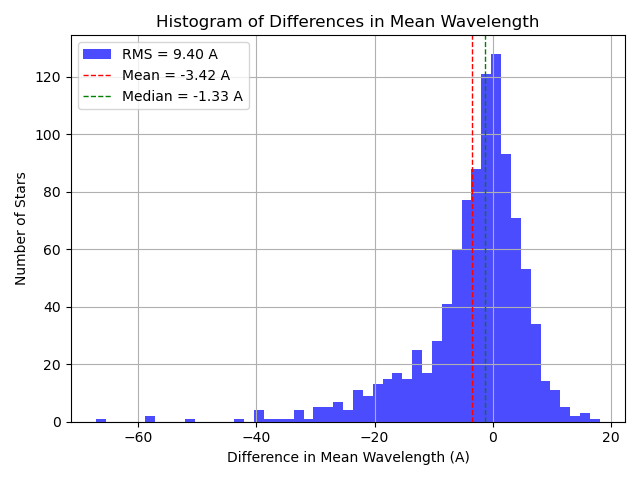

In [ ]:

fig = plt.figure()
plt.hist(snls['wl_diff'], bins='fd', color='blue', alpha=0.7, label='RMS = {:.2f} A'.format(np.std(snls['wl_diff'].dropna())))
plt.axvline(np.mean(snls['wl_diff'].dropna()), color='red', linestyle='dashed', linewidth=1, label=f'Mean = {np.mean(snls['wl_diff'].dropna()):.2f} A')
plt.axvline(np.median(snls['wl_diff'].dropna()), color='green', linestyle='dashed', linewidth=1, label=f'Median = {np.median(snls['wl_diff'].dropna()):.2f} A')
plt.legend()
plt.xlabel('Difference in Mean Wavelength (A)')
plt.ylabel('Number of Stars')
plt.title('Histogram of Differences in Mean Wavelength')
plt.grid()
fig.tight_layout()
plt.show()

## BACKUP IRREGULAR INTERPOLATOR

In [ ]:
def create_fast_4d_interpolator_knn(ambre_data, n_neighbors=4):
    """
    Créer un interpolateur 4D rapide avec KNN
    """
    from sklearn.neighbors import KNeighborsRegressor
    import numpy as np
    
    print("Création d'un interpolateur 4D rapide avec KNN...")
    
    # Extraire tous les points et flux
    all_points = []
    all_flux = []
    
    for idx, row in tqdm(ambre_data.iterrows(), total=len(ambre_data), desc="Préparation données KNN"):
        teff = row['teff']
        logg = row['logg'] 
        mh = row['mh']
        wave_binned = row['wave_binned']
        flux_binned = row['flux_binned']
        
        # Créer les points 4D pour ce spectre
        for wave, flux in zip(wave_binned, flux_binned):
            if not np.isnan(flux):
                all_points.append([teff, logg, mh, wave])
                all_flux.append(flux)
    
    points = np.array(all_points)
    values = np.array(all_flux)
    
    print(f"Points d'interpolation: {len(points):,}")
    
    # Créer le modèle KNN
    knn = KNeighborsRegressor(
        n_neighbors=n_neighbors, 
        weights='distance',  # Pondération par distance
        algorithm='ball_tree',  # Plus rapide pour haute dimension
        leaf_size=30
    )
    
    print("Entraînement du modèle KNN...")
    knn.fit(points, values)
    
    return knn, points, values

def ambre_knn_spectrum_interpolator(knn_model, wavelengths, teff, logg, mh):
    """Interface pour l'interpolateur KNN"""
    wavelengths = np.asarray(wavelengths)
    
    query_points = np.column_stack([
        np.full(len(wavelengths), teff),
        np.full(len(wavelengths), logg),
        np.full(len(wavelengths), mh),
        wavelengths
    ])
    
    flux_interp = knn_model.predict(query_points)
    return flux_interp


def create_fast_4d_interpolator_kdtree(ambre_data):
    """
    Interpolateur basé sur cKDTree (plus proche voisin rapide)
    """
    from scipy.spatial import cKDTree
    
    print("Création d'un interpolateur 4D avec cKDTree...")
    
    all_points = []
    all_flux = []
    
    for idx, row in tqdm(ambre_data.iterrows(), total=len(ambre_data), desc="Préparation cKDTree"):
        teff = row['teff']
        logg = row['logg'] 
        mh = row['mh']
        wave_binned = row['wave_binned']
        flux_binned = row['flux_binned']
        
        for wave, flux in zip(wave_binned, flux_binned):
            if not np.isnan(flux):
                all_points.append([teff, logg, mh, wave])
                all_flux.append(flux)
    
    points = np.array(all_points)
    values = np.array(all_flux)
    
    # Créer l'arbre KD
    tree = cKDTree(points)
    
    return tree, points, values

def ambre_kdtree_spectrum_interpolator(tree, points, values, wavelengths, teff, logg, mh, k=4):
    """Interface pour l'interpolateur cKDTree avec moyenne pondérée"""
    wavelengths = np.asarray(wavelengths)
    
    query_points = np.column_stack([
        np.full(len(wavelengths), teff),
        np.full(len(wavelengths), logg),
        np.full(len(wavelengths), mh),
        wavelengths
    ])
    
    # Trouver les k plus proches voisins
    distances, indices = tree.query(query_points, k=k)
    
    # Éviter division par zéro
    distances = np.maximum(distances, 1e-10)
    
    # Pondération inverse de la distance
    weights = 1.0 / distances
    weights_sum = np.sum(weights, axis=1, keepdims=True)
    weights_norm = weights / weights_sum
    
    # Interpolation pondérée
    flux_interp = np.sum(weights_norm * values[indices], axis=1)
    
    return flux_interp


# Test de performance
if 'ambre_complete' in locals():
    import time
    
    print("=== COMPARAISON DES MÉTHODES D'INTERPOLATION ===")
    
    # Test KNN
    start = time.time()
    knn_model, points_knn, values_knn = create_fast_4d_interpolator_knn(ambre_complete.head(100))
    knn_time = time.time() - start
    print(f"KNN setup: {knn_time:.2f}s")
    
    # Test cKDTree
    start = time.time()
    tree, points_tree, values_tree = create_fast_4d_interpolator_kdtree(ambre_complete.head(100))
    kdtree_time = time.time() - start
    print(f"cKDTree setup: {kdtree_time:.2f}s")
    
    # Test interpolation
    test_wave = np.array([4000, 5000, 6000, 7000])
    
    start = time.time()
    flux_knn = ambre_knn_spectrum_interpolator(knn_model, test_wave, 5800, 4.4, 0.0)
    knn_interp_time = time.time() - start
    
    start = time.time()
    flux_kdtree = ambre_kdtree_spectrum_interpolator(tree, points_tree, values_tree, test_wave, 5800, 4.4, 0.0)
    kdtree_interp_time = time.time() - start
    
    print(f"\nTemps d'interpolation:")
    print(f"KNN: {knn_interp_time*1000:.2f}ms")
    print(f"cKDTree: {kdtree_interp_time*1000:.2f}ms")
    
    print(f"\nRésultats:")
    print(f"KNN: {flux_knn}")
    print(f"cKDTree: {flux_kdtree}")

=== COMPARAISON DES MÉTHODES D'INTERPOLATION ===
Création d'un interpolateur 4D rapide avec KNN...


Préparation données KNN: 100%|██████████| 100/100 [00:00<00:00, 122.10it/s]


Points d'interpolation: 900,000
Entraînement du modèle KNN...
KNN setup: 1.79s
Création d'un interpolateur 4D avec cKDTree...


Préparation cKDTree: 100%|██████████| 100/100 [00:00<00:00, 106.29it/s]


cKDTree setup: 1.28s

Temps d'interpolation:
KNN: 1.08ms
cKDTree: 0.67ms

Résultats:
KNN: [ 997.43975 1465.1251  3397.45595 4041.1295 ]
cKDTree: [1029.1841   944.09175 2543.19965 4452.4815 ]


: 

In [ ]:
def create_irregular_4d_interpolator(ambre_data):
    """
    Créer un interpolateur 4D pour grille irrégulière AMBRE
    """
    from scipy.interpolate import LinearNDInterpolator
    
    print("Création d'un interpolateur 4D pour grille irrégulière...")
    
    # Extraire tous les points (teff, logg, mh, wavelength) et flux
    all_points = []
    all_flux = []
    
    for idx, row in tqdm(ambre_data.iterrows(), total=len(ambre_data), desc="Préparation données"):
        teff = row['teff']
        logg = row['logg'] 
        mh = row['mh']
        wave_binned = row['wave_binned']
        flux_binned = row['flux_binned']
        
        # Créer les points 4D pour ce spectre
        for i, (wave, flux) in enumerate(zip(wave_binned, flux_binned)):
            if not np.isnan(flux):  # Exclure les NaN
                all_points.append([teff, logg, mh, wave])
                all_flux.append(flux)
    
    # Convertir en arrays numpy
    points = np.array(all_points)
    values = np.array(all_flux)
    
    print(f"Points d'interpolation: {len(points):,}")
    print(f"Plages des paramètres:")
    print(f"  Teff: {points[:,0].min():.0f} - {points[:,0].max():.0f} K")
    print(f"  log g: {points[:,1].min():.1f} - {points[:,1].max():.1f}")
    print(f"  [M/H]: {points[:,2].min():.1f} - {points[:,2].max():.1f}")
    print(f"  Wavelength: {points[:,3].min():.0f} - {points[:,3].max():.0f} Å")
    
    # Créer l'interpolateur
    interpolator = LinearNDInterpolator(points, values, fill_value=np.nan)
    
    return interpolator, points, values

def ambre_irregular_spectrum_interpolator(interpolator, wavelengths, teff, logg, mh):
    """
    Fonction d'interface pour l'interpolateur irrégulier
    """
    wavelengths = np.asarray(wavelengths)
    
    # Créer les points d'interrogation
    query_points = np.column_stack([
        np.full(len(wavelengths), teff),
        np.full(len(wavelengths), logg),
        np.full(len(wavelengths), mh),
        wavelengths
    ])
    
    # Interpoler
    flux_interp = interpolator(query_points)
    
    return flux_interp

# Utilisation
if 'ambre_complete' in locals():
    # Créer l'interpolateur irrégulier
    irregular_interp, points, values = create_irregular_4d_interpolator(ambre_complete)
    
    # Test
    test_wave = np.array([4000, 5000, 6000, 7000])
    test_flux = ambre_irregular_spectrum_interpolator(irregular_interp, test_wave, 5800, 4.4, 0.0)
    
    print(f"\nTest interpolation irrégulière:")
    print(f"Wavelengths: {test_wave}")
    print(f"Flux: {test_flux}")

Création d'un interpolateur 4D pour grille irrégulière...


Préparation données: 100%|██████████| 12927/12927 [02:00<00:00, 107.09it/s]


Points d'interpolation: 116,343,000
Plages des paramètres:
  Teff: 3500 - 8000 K
  log g: 0.0 - 5.5
  [M/H]: -5.0 - 1.0
  Wavelength: 3000 - 12000 Å
